# Historical Senate predictions: 2022 and 2024

Compare the market and each model with the final election result at 12 dates, from June 1 to November 3, including September 5 and 20. **Prediction accuracy, model–market distance, an exploratory long-shot exit-price proxy test, and an independent-model positive-EV strategy.** Everything is generated by Python; no AI calls.

[Methodology](../docs/POLYMARKET_BACKTEST.md) · [Latest report](../outputs/reports/research/polymarket_history/report.md)

Run `scripts/prepare_historical_markets.py` once to download the data. Subsequent runs use local data and cached historical inference. Changed model code or inputs invalidate inference caches automatically. Raw data and inference outputs are Git-ignored.

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'election_lab.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown, Image
from download_polymarket_history import collect, OUT
from polymarket_backtest import build

# Downloads and analysis are independent. Normal reruns use locally downloaded tables.
DOWNLOAD_MARKETS = False
DOWNLOAD_PUBLISHERS = False
RECHECK_CACHED_MARKET_RESPONSES = False
if DOWNLOAD_MARKETS:
    collect(refresh=RECHECK_CACHED_MARKET_RESPONSES)
if DOWNLOAD_PUBLISHERS:
    from polymarket_signal_publishers import collect_extended as collect_publishers
    collect_publishers()
if not (OUT / 'collection.json').exists():
    raise FileNotFoundError('Research data is Git-ignored. Run .venv/bin/python scripts/prepare_historical_markets.py first.')
research = build()

def table(frame):
    with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', None):
        display(frame.style.hide(axis='index').format(precision=3, na_rep='—'))
print('Historical inference uses dated evidence and frozen earlier-cycle fits. Cached runs are reused when inputs and code match.')

Historical inference uses dated evidence and frozen earlier-cycle fits. Cached runs are reused when inputs and code match.


## Debounced winner setups — current study

Count one setup per model and state race until its edge disappears on two consecutive valid daily checks. Repeated signals and equivalent party contracts no longer create additional entries. The same timing, 2¢ entry threshold and three-day forecast-age limit apply to our models and publishers.

The observation window ends at confirmed reset or the pre-election cutoff. **Maximum sustained rise** is the best three-day price rise within that window, measured with hindsight. It is evidence of a possible favorable move, not a simulated sale or earned return. **Endpoint change** is the price change at the end of the window. Full-path summaries exclude inadequately observed windows; witnessed partial hits remain visible. Daily price changes and raw maxima are saved for inspection.

The older daily-observation and twelve-date studies below are retained for reference and use different denominators.

The **Observed** table includes partial windows with at least one qualifying three-day sequence. Its observed maximum is a lower bound on the full-path maximum. The other return summaries and target percentages use full paths only.

In [3]:
from polymarket_debounced_signals import build as build_debounced, METHOD as DEBOUNCED_METHOD, display_tables
from polymarket_signal_quality import MODEL_LABELS
debounced = build_debounced()
display(Markdown(DEBOUNCED_METHOD))
table(pd.DataFrame(MODEL_LABELS.items(),columns=['Code','Model']))
for cycle, rows in debounced['overall'].groupby('cycle'):
    display(Markdown(f'### {cycle}: distinct setups and hindsight path diagnostics'))
    for view in display_tables(rows):
        table(view)
    table(rows[['model','mean_raw_max_cents','mean_worst_cents','median_sustained_return_pct']].rename(columns={
        'model':'Model','mean_raw_max_cents':'Mean raw max (¢)','mean_worst_cents':'Mean worst change (¢)',
        'median_sustained_return_pct':'Median max sustained (%)'}))
for key, band in [('probabilities','probability_band'),('time','time_band'),('activity','activity_band'),('states','state')]:
    for (cycle,label), rows in debounced[key].groupby(['cycle',band]):
        display(Markdown(f'#### {cycle}: {key} — {label}'))
        for view in display_tables(rows):
            table(view)
print('Debounced report:',debounced['report'].relative_to(ROOT))
print('Saved setup rows: outputs/results/research/polymarket_history/debounced_win_episodes.parquet')
print('Saved daily checks and price paths: debounced_win_decisions.parquet and debounced_win_paths.parquet in the same folder.')

 cycle model  setups  states  complete  observed_sustained_paths  observed_mean_sustained_cents  observed_median_sustained_cents  partial_hits  unknown  mean_sustained_cents  median_sustained_cents  median_sustained_return_pct  median_edge_coverage  mean_endpoint_cents  mean_raw_max_cents  mean_worst_cents  hit_5_pct  hit_10_pct  hit_20_pct  hit_50_pct  hit_edge_pct
  2022   538      20      13         8                        17                          1.544                            1.735             1       11                 0.770                   0.289                        0.336                 0.043               -3.096               4.515            -9.094     25.000       0.000       0.000       0.000         0.000
  2022  538C      17      13         6                        15                          3.182                            1.735             1       10                 4.131                   1.878                        2.747                 0.145              

One setup per model and state race, not per forecast day. Use one fixed representative regular-winner contract per state/cycle: Democratic-first if available, then lowest numeric market ID; selection never uses future price performance. Other compatible contracts are audited, not counted again. This groups equivalent party exposure rather than claiming cross-contract arbitrage.

Check daily at 00:00 UTC, starting September 2 (September 1 forecasts become available then), strictly before election-day midnight. Use the latest already-available forecast, at most 72 hours after its labelled forecast date, and the latest price strictly before the decision, at most 36 hours old. Retain original source dates: a carried publisher forecast is not a new forecast. Superseded publisher versions cannot be used. Apply identical timing rules to all models.

Enter when the selected side's probability-minus-price edge exceeds 2 cents. Keep one active setup until its edge is nonpositive on two consecutive valid daily checks with distinct price observations. Missing/stale forecasts or quotes break reset confirmation but do not close or rearm a setup. Opposite-side entry must wait until a later daily check after reset. Hitting a price target does not rearm the signal. Close the observation window at confirmed reset or the pre-election cutoff; never optimize its length from future prices.

For each nonoverlapping setup, report the raw maximum observed rise and the maximum rise sustained across three consecutive UTC calendar days (at least 36-hour span and gaps no greater than 36 hours), plus fresh endpoint change and worst observed change. Maxima are hindsight diagnostics, not achievable sale prices or realized profits. Return percentages divide price change by starting share price; edge coverage divides it by initial model edge. Primary mean/median maxima use fully observed windows only (at least three possible subsequent days, 80% daily coverage, and a valid endpoint within 36 hours). Partial-path witnessed hits remain separate; absent evidence is unknown, not failure. Targets are 5/10/20/50% of entry price with a 2-cent floor, or the larger of initial edge and 2 cents. Daily path files save adjacent-day changes without filling missing days. Prices are research proxies, not executable quotes; no fees, order fills or position sizing are assumed. Different model coverage remains relevant; repeated races across models are not independent evidence.

Code,Model
GB,Gaussian Bayesian
ST,Matched Student-t
OG,Older Gaussian
OS,Older Student-t
MX,Four-model mixture
M10,Mixture with 10% polling mean shift
538,538 Deluxe
538C,538 Classic
538L,538 Lite
ECON,Economist original


### 2022: distinct setups and hindsight path diagnostics

Model,Setups,States,Full paths,Partial hits (10%),Unknown (10%)
538,20,13,8,1,11
538C,17,13,6,1,10
538L,15,13,5,1,9
ECON,4,4,3,0,1
GB,13,11,2,1,10
M10,17,11,4,0,13
MX,18,11,6,0,12
OG,15,11,3,2,10
OS,15,11,5,1,9
ST,16,11,3,0,13


Model,Observed 3-day paths,Observed mean max (¢),Observed median max (¢)
538,17,1.544,1.735
538C,15,3.182,1.735
538L,13,2.345,0.289
ECON,4,0.360,0.760
GB,11,1.868,0.289
M10,14,0.853,0.181
MX,15,1.112,0.074
OG,14,2.544,0.181
OS,15,1.923,0.872
ST,12,1.191,0.181


... (326 outputs left out)

Model,Observed 3-day paths,Observed mean max (¢),Observed median max (¢)
DDHQ,3,0.667,3.000
GB,1,16.500,16.500
M10,2,-1.000,-1.000
MX,2,4.750,4.750
OG,2,4.750,4.750
OS,1,1.500,1.500
RTWH,1,-1.500,-1.500
ST,2,-1.000,-1.000


Model,Mean max sustained (¢),Median max sustained (¢),Mean endpoint (¢),Median edge covered (×)
DDHQ,0.667,3.000,3.333,0.664
GB,16.500,16.500,7.000,1.312
M10,-1.000,-1.000,3.500,-0.874
MX,4.750,4.750,8.750,0.842
OG,4.750,4.750,9.000,1.238
OS,1.500,1.500,-7.500,0.726
RTWH,-1.500,-1.500,-4.000,-0.500
ST,-1.000,-1.000,3.500,-1.243


Model,5% target,10% target,20% target,50% target,Edge target
DDHQ,33.333,33.333,33.333,0.000,33.333
GB,100.000,100.000,100.000,100.000,100.000
M10,50.000,50.000,50.000,0.000,50.000
MX,50.000,50.000,50.000,0.000,50.000
OG,50.000,50.000,50.000,0.000,50.000
OS,0.000,0.000,0.000,0.000,0.000
RTWH,0.000,0.000,0.000,0.000,0.000
ST,50.000,50.000,50.000,0.000,0.000


Debounced report: outputs/reports/research/polymarket_history/debounced_win_signals.md
Saved setup rows: outputs/results/research/polymarket_history/debounced_win_episodes.parquet
Saved daily checks and price paths: debounced_win_decisions.parquet and debounced_win_paths.parquet in the same folder.


## Earlier daily observations — repeated signals included

This section uses the saved daily forecasts for September through election eve in both cycles. It tests each model separately and follows prices until the pre-election cutoff. It does not require thirty days of follow-up. The older twelve-date experiments below remain for reference and use different sampling and scoring rules.

**Signals** are dated positive-edge observations, not independent trades. **Full paths** have enough coverage through the remaining pre-election window. **Unknown** paths have neither adequate coverage nor a confirmed hit. The target percentages are relative price rises, each with a 2¢ minimum, sustained across three daily observations. These are potential setups, not realized profits.

In [4]:
from polymarket_daily_win_signals import build as build_daily_wins, METHOD as DAILY_WIN_METHOD, rates as daily_rates
from polymarket_signal_quality import MODEL_LABELS
wins = build_daily_wins()
display(Markdown(DAILY_WIN_METHOD))
table(pd.DataFrame(MODEL_LABELS.items(), columns=['Code','Model']))
for cycle, rows in wins['overall'].groupby('cycle'):
    display(Markdown(f'### {cycle}: coverage and sustained target rates'))
    view = daily_rates(rows)
    table(view[['Model','Signals','Markets','Full paths','Unknown']])
    table(view[['Model','5%','10%','20%','50%']])
    display(Markdown('**10% target: all confirmed moves, including incomplete paths.**'))
    table(rows[rows.target.eq('10%')][['model','confirmed','partial_hits','episodes','days_to_hit']].rename(columns={
        'model':'Model','confirmed':'Confirmed','partial_hits':'Partial-path hits','episodes':'Signal episodes','days_to_hit':'Median days to hit'}))
for key, band, title in [('time','time_band','Time remaining'),('probabilities','probability_band','Starting price'),
                         ('activity','activity_band','Prior activity'),('edges','edge_band','Initial edge'),('states','state','State')]:
    for (cycle, label), rows in wins[key].groupby(['cycle',band]):
        display(Markdown(f'#### {cycle}: {title} — {label}'))
        view = daily_rates(rows)
        table(view[['Model','Signals','Markets','Full paths','Unknown']])
        table(view[['Model','5%','10%','20%','50%']])
display(Markdown('### Same-market, same-date comparisons (10% target)'))
for cycle, rows in wins['paired'].groupby('cycle'):
    display(Markdown(f'#### {cycle}'))
    table(rows.drop(columns='cycle'))
print('Daily winner report:', wins['report'].relative_to(ROOT))
print('Case-level results: outputs/results/research/polymarket_history/daily_win_signals_detail.parquet')

 cycle model  signals  complete  confirmed  partial_hits  unknown  hit_pct
  2022   538      560       337         73            22      201    15.13
  2022  538C      560       337         57            17      206    11.87
  2022  538L      560       337         56            20      203    10.68
  2022  ECON      129       113         21             0       16    18.58
  2022    GB      442       225         25            17      200     3.56
  2022   M10      442       225         52            41      176     4.89
  2022    MX      442       225         51            39      178     5.33
  2022    OG      442       225         79            48      169    13.78
  2022    OS      442       225         56            42      175     6.22
  2022    ST      442       225         27            20      197     3.11
  2024  DDHQ     3478      3304        683             0      174    20.67
  2024    GB     3456      3294        485             0      162    14.72
  2024   M10     3456    

Use the saved September-to-election daily forecast table, separately for each model. Only reviewed regular state-winner contracts are eligible; missing publisher days are not filled. Each forecast becomes usable after its labelled day ends UTC. The first valid price within 36 hours is the reference, strictly before election-day 00:00 UTC. Both outcome orientations are mapped explicitly. A positive probability-minus-price edge selects the side; this is before fees, not executable positive EV.

Follow every signal until election-day 00:00 UTC, without requiring a 30-day window. Targets are 5%, 10%, 20%, 50% of starting price (each at least 2 cents), plus the larger of initial edge and 2 cents. A hit must persist across three consecutive observed UTC days spanning at least 36 hours, with gaps no greater than 36 hours. No inactive days are filled. A fully observed remaining window requires at least three possible daily observations, at least 80% daily coverage and a valid last price within 36 hours of cutoff. Missing/too-short paths are unknown, not failures. Confirmed hits in incomplete windows are retained separately. Rates use full windows only; confirmed/all-signals is a lower bound when paths are missing.

Longer remaining windows offer more time to hit. Report time-to-election bands, initial prices, initial edges, prior seven-day activity and state subsets. Repeated daily signals and multiple contracts for one race are correlated; counts are not independent trades. Consecutive same-side daily signals are grouped as episodes for context, not used to assume an entry/exit strategy. Market prices may be reconstructed pool probabilities or last-trade proxies, not executable quotes. These are retrospective potential setups, not earned profits. Frozen local calibration and incomplete publication-vintage reconstruction still apply.

Code,Model
GB,Gaussian Bayesian
ST,Matched Student-t
OG,Older Gaussian
OS,Older Student-t
MX,Four-model mixture
M10,Mixture with 10% polling mean shift
538,538 Deluxe
538C,538 Classic
538L,538 Lite
ECON,Economist original


### 2022: coverage and sustained target rates

Model,Signals,Markets,Full paths,Unknown
GB,442.000,11.000,225.000,200.000
ST,442.000,11.000,225.000,197.000
OG,442.000,11.000,225.000,169.000
OS,442.000,11.000,225.000,175.000
MX,442.000,11.000,225.000,178.000
M10,442.000,11.000,225.000,176.000
538,560.000,13.000,337.000,201.000
538C,560.000,13.000,337.000,206.000
538L,560.000,13.000,337.000,203.000
ECON,129.000,4.000,113.000,16.000


Model,5%,10%,20%,50%
GB,9.800,3.600,0.900,0.900
ST,9.300,3.100,0.400,0.400
OG,20.400,13.800,10.700,9.300
OS,12.400,6.200,3.600,2.700
MX,11.600,5.300,2.700,2.700
M10,11.100,4.900,2.200,2.200
538,22.800,15.100,12.500,4.200
538C,20.500,11.900,7.100,0.900
538L,19.300,10.700,5.900,0.600
ECON,27.400,18.600,14.200,0.000


... (243 outputs left out)

model_a,model_b,observations,markets,hit_a,hit_b
538,538C,337,13,15.134,11.869
538,538L,337,13,15.134,10.682
538,ECON,113,4,29.204,18.584
538,GB,225,11,4.889,3.556
538,M10,225,11,4.889,4.889
538,MX,225,11,4.889,5.333
538,OG,225,11,4.889,13.778
538,OS,225,11,4.889,6.222
538,ST,225,11,4.889,3.111
538C,538L,337,13,11.869,10.682


#### 2024

model_a,model_b,observations,markets,hit_a,hit_b
DDHQ,GB,3076,54,19.603,14.857
DDHQ,M10,3076,54,19.603,11.671
DDHQ,MX,3076,54,19.603,11.183
DDHQ,OG,3076,54,19.603,11.638
DDHQ,OS,3076,54,19.603,7.737
DDHQ,RTWH,611,56,19.149,5.728
DDHQ,ST,3076,54,19.603,10.728
GB,M10,3294,54,14.724,11.506
GB,MX,3294,54,14.724,10.990
GB,OG,3294,54,14.724,11.627


Daily winner report: outputs/reports/research/polymarket_history/daily_win_signals.md
Case-level results: outputs/results/research/polymarket_history/daily_win_signals_detail.parquet


## Models and timing

Our models rerun at every displayed date using the frozen September 17 calibration and fits trained on earlier election cycles. They receive polls and reference-period features available under each cutoff rule. Known later poll releases are excluded; unknown release dates use field-end dates. Some features are latest-vintage revisions. These are retrospective reconstructions, not forecasts published at the time. The model design was developed later, and calibration across these different horizons is not separately validated.

Third-party forecasts use the latest available snapshot on or before each check date, at most six days old. The market observation must precede the end of the check date and be no more than seven days old. Actual observation dates appear below. Missing data stays blank.

2022 pool probabilities are reconstructed from original trades and liquidity changes. 2024 uses archived price histories where available. Last-trade proxies are a fallback. None of these are executable bid/ask quotes.

In [5]:
table(pd.DataFrame([
    ['GB','Gaussian Bayesian'], ['ST','Matched Student-t'],
    ['MX','Four-model mixture'], ['M10','Mixture shifted 10% toward polling'],
    ['RTWH','Race to the WH, historical 2024'], ['538','FiveThirtyEight Deluxe, historical 2022'],
], columns=['Code','Model']))


Code,Model
GB,Gaussian Bayesian
ST,Matched Student-t
MX,Four-model mixture
M10,Mixture shifted 10% toward polling
RTWH,"Race to the WH, historical 2024"
538,"FiveThirtyEight Deluxe, historical 2022"


## Data sources

In [6]:
table(research['coverage'].rename(columns={'cycle':'Cycle','price_source':'Source','contracts':'Markets','points':'Daily points'}))
if (OUT / 'publisher_status.parquet').exists():
    table(pd.read_parquet(OUT / 'publisher_status.parquet')[['model','cycle','status','rows','first','last']])

Cycle,Source,Markets,Daily points
2022,"Reconstructed FPMM marginal probability, before fees",36,2654
2024,Last on-chain execution probability proxy; outcome 1 complemented when used,5,47
2024,Original archived CLOB price-history observation; not an executable quote,164,24000


model,cycle,status,rows,first,last
RTWH,2024,available,2378,2023-10-01,2024-11-05
538,2022,available,4896,2022-06-01,2022-11-08


## Overall accuracy and distance from the market

Lower **Brier** means better predictions against the observed winner. Lower **Gap (pp)** means closer to the market. Closer does not automatically mean more accurate.

At each date, all displayed models use the same priced states. Coverage can change across dates. The overall proximity ranking uses states shared by every model, weights those states equally and uses dates shared by all available models within each state. Repeated dates reuse election outcomes and are not independent tests. “Overall” refers to accuracy across states, not Senate-control probability.

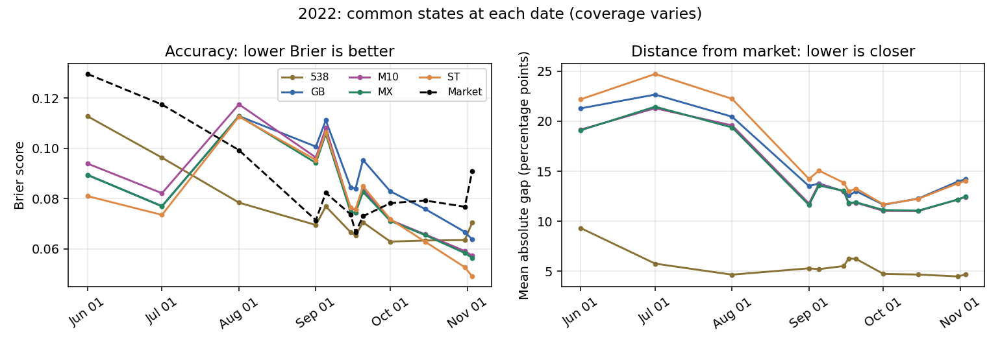

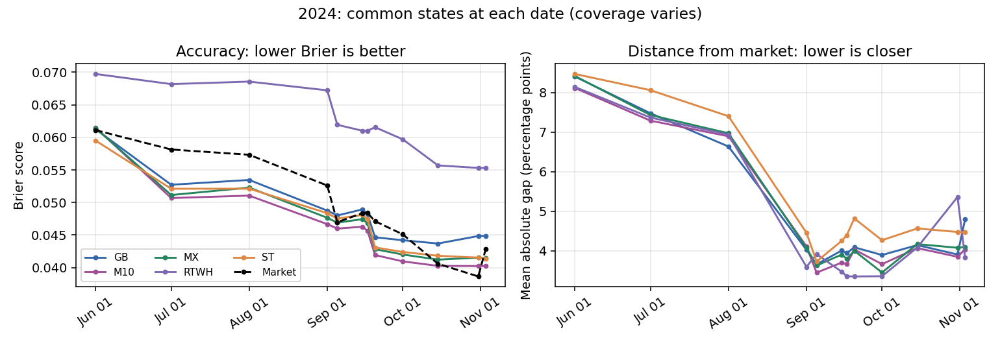

### 2022 — Jun 01

Model,States,Brier,Market Brier,Gap (pp)
538,7,0.113,0.130,9.320
GB,7,0.090,0.130,21.286
M10,7,0.094,0.130,19.162
MX,7,0.089,0.130,19.095
ST,7,0.081,0.130,22.190


### 2022 — Jul 01

Model,States,Brier,Market Brier,Gap (pp)
538,7,0.096,0.117,5.764
GB,7,0.077,0.117,22.667
M10,7,0.082,0.117,21.299
MX,7,0.077,0.117,21.456
ST,7,0.074,0.117,24.725


### 2022 — Aug 01

Model,States,Brier,Market Brier,Gap (pp)
538,7,0.078,0.099,4.660
GB,7,0.113,0.099,20.456
M10,7,0.118,0.099,19.586
MX,7,0.113,0.099,19.379
ST,7,0.113,0.099,22.243


... (42 outputs left out)

### 2022 — models closest to the market

Model,States,Gap (pp),Brier
538,11,5.324,0.065
M10,11,12.951,0.071
MX,11,12.971,0.070
GB,11,13.861,0.078
ST,11,14.366,0.069


### 2024 — models closest to the market

Model,States,Gap (pp),Brier
RTWH,26,4.730,0.062
M10,26,4.738,0.046
MX,26,4.834,0.047
GB,26,4.913,0.049
ST,26,5.279,0.047


In [7]:
from polymarket_history_samples import state_comparison_table, proximity, overall_proximity
samples = research['date_samples']
for path in research['charts']:
    if path.name.startswith('prediction_comparison'):
        display(Image(filename=str(path)))
for (cycle, date), group in research['scores'].groupby(['cycle','check_date']):
    display(Markdown(f'### {cycle} — {date:%b %d}'))
    table(group[['model','priced_states','model_brier','market_brier','gap_pp']].rename(columns={
        'model':'Model','priced_states':'States','model_brier':'Brier','market_brier':'Market Brier','gap_pp':'Gap (pp)'}))
near = research['state_proximity']
for cycle, group in near.groupby('cycle'):
    display(Markdown(f'### {cycle} — models closest to the market'))
    rank = overall_proximity(group).rename(columns={'model':'Model','states':'States','gap_pp':'Gap (pp)','brier':'Brier'})
    table(rank)


## Earlier twelve-date study: every model on its own available observations

Local models use reconstructed check dates. Publishers use every recovered dated snapshot. Models need not share states or dates. Missing models remain visible as blank rows. Rates use complete paths; counts include repeated observations and are not independent trades. The tables cover both cycles, all models, and starting-probability, prior-activity, initial-edge and state subsets.

In [8]:
from polymarket_signal_quality import AVAILABLE_METHOD, MODEL_LABELS, available_table, available_coverage
signal = research['signals']
display(Markdown(AVAILABLE_METHOD))
table(pd.DataFrame(MODEL_LABELS.items(),columns=['Code','Model']))
for (cycle, days), rows in signal['available_overall'].groupby(['cycle','horizon']):
    display(Markdown(f'### {cycle}: {days}-day targets — all models'))
    table(available_table(rows))
    if days == 30:
        display(Markdown('**Coverage:**'))
        table(available_coverage(rows))
        display(Markdown('**Confirmed sustained setups, including incomplete-path witnesses:**'))
        table(available_table(rows,counts=True))
for key, grouping, label in [
    ('probabilities','probability_band','Starting probability'),
    ('activities','activity_band','Prior seven-day activity'),
    ('edges','edge_band','Initial edge'),
    ('states','state','State')]:
    for (cycle, subset), rows in signal['available_'+key].query('horizon==30').groupby(['cycle',grouping]):
        if rows.signals.sum()==0:
            continue
        display(Markdown(f'#### {cycle}: {label} — {subset} (30 days)'))
        table(available_table(rows))
print('Standalone complete tables:', (research['report'].parent / 'all_models.md').relative_to(ROOT))

Each model uses its own available observations. Our six local models use their twelve reconstructed forecast dates; publishers use every recovered dated snapshot. Publisher shared-date rows are excluded here to avoid double-counting. No common-state, common-date or minimum-sample filter is imposed. Missing models are displayed explicitly. These tables are descriptive comparisons, not a matched-sample ranking: different dates, markets and signal sides can explain differences.

All signals have positive model edge. Columns show sustained Edge, 5%, 10%, 20% and 50% targets, with a 2-cent minimum and three consecutive observed days. Percentages use complete windows only; the coverage table and witnessed-setup tables also retain incomplete paths. N / markets means complete forecast observations / distinct markets contributing to that row. Overlapping dates are not independent trades. A blank rate is unscored, not zero. Subsets use the purchased side's initial probability, strictly prior seven-day trading activity, and initial edge; none uses the final election outcome. Activity is not executable liquidity. Targets above $1 remain in the denominator.

Code,Model
GB,Gaussian Bayesian
ST,Matched Student-t
OG,Older Gaussian
OS,Older Student-t
MX,Four-model mixture
M10,Mixture with 10% polling mean shift
538,538 Deluxe
538C,538 Classic
538L,538 Lite
ECON,Economist original


### 2022: 7-day targets — all models

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
GB,8 / 6,0.000,12.500,0.000,0.000,0.000
ST,8 / 6,12.500,12.500,0.000,0.000,0.000
OG,8 / 6,12.500,12.500,0.000,0.000,0.000
OS,8 / 6,0.000,12.500,0.000,0.000,0.000
MX,8 / 6,12.500,12.500,0.000,0.000,0.000
M10,8 / 6,12.500,12.500,0.000,0.000,0.000
538,228 / 11,6.579,17.982,7.018,2.632,0.439
538C,228 / 11,5.263,17.982,6.579,2.632,0.877
538L,228 / 11,1.316,14.912,6.140,2.193,0.877
ECON,68 / 4,0.000,11.765,1.471,0.000,0.000


### 2022: 14-day targets — all models

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
GB,4 / 3,0.000,0.000,0.000,0.000,0.000
ST,4 / 3,0.000,0.000,0.000,0.000,0.000
OG,4 / 3,0.000,0.000,0.000,0.000,0.000
OS,4 / 3,0.000,0.000,0.000,0.000,0.000
MX,4 / 3,0.000,0.000,0.000,0.000,0.000
M10,4 / 3,0.000,0.000,0.000,0.000,0.000
538,148 / 8,13.514,24.324,12.838,7.432,0.676
538C,148 / 8,11.486,20.946,8.108,2.027,0.676
538L,148 / 8,0.000,14.865,6.757,2.027,0.676
ECON,70 / 4,0.000,14.286,5.714,0.000,0.000


... (149 outputs left out)

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
GB,9 / 1,22.222,55.556,55.556,44.444,22.222
ST,9 / 1,33.333,66.667,66.667,44.444,22.222
OG,9 / 1,55.556,66.667,66.667,44.444,22.222
OS,9 / 1,0.000,11.111,11.111,0.000,0.000
MX,9 / 1,44.444,66.667,66.667,44.444,22.222
M10,9 / 1,33.333,66.667,66.667,44.444,22.222
538,—,—,—,—,—,—
538C,—,—,—,—,—,—
538L,—,—,—,—,—,—
ECON,—,—,—,—,—,—


#### 2024: State — WY (30 days)

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
GB,9 / 1,0.000,0.000,0.000,0.000,0.000
ST,9 / 1,0.000,0.000,0.000,0.000,0.000
OG,9 / 1,0.000,0.000,0.000,0.000,0.000
OS,9 / 1,0.000,0.000,0.000,0.000,0.000
MX,9 / 1,0.000,0.000,0.000,0.000,0.000
M10,9 / 1,0.000,0.000,0.000,0.000,0.000
538,—,—,—,—,—,—
538C,—,—,—,—,—,—
538L,—,—,—,—,—,—
ECON,—,—,—,—,—,—


Standalone complete tables: outputs/reports/research/polymarket_history/all_models.md


## Signal quality: did the edge precede a sustained price increase?

This is the main signal experiment. It uses all six local models and every validated publisher series we recovered. It does not choose an exit, calculate trading profit, or combine model votes. **Target (%)** means the price rose by at least the initial edge and at least 2¢, sustained across three consecutive daily observations. **Scored** excludes incomplete or post-election windows; **Scored markets** counts only markets contributing to that result.

The largest sustained rise is a hindsight diagnostic. Different edges set different targets, so compare the rise and ending change as well as target rates. Overlapping dates reuse the same races. Liquidity below means a past-activity proxy, not executable depth.

Each model is evaluated separately at the same twelve historical check dates. Local forecasts must match the check date. Publisher forecasts must be dated on or before it and at most six days old; superseded versions are excluded. A forecast is usable after its dated day ends (UTC). The reference price is the first valid daily observation within the following 36 hours. No final result or future model update selects a signal. Both sides are retained as controls; a positive edge is initial model probability minus initial side price, without fees or an assumed trade.

We follow prices for 7, 14 and 30 days, strictly before the election. A sustained level is the lowest of three consecutive daily observations, spanning at least 36 hours, with no gap above 36 hours and no invalid observation between them. The largest such level is a hindsight path diagnostic, not a chosen exit. A qualifying move exceeds the larger of the initial positive edge and a 2-cent noise floor. Sensitivities use 1/2/3 cents and 2/3/5 consecutive observations. Days after the election are never substituted for a missing horizon. Primary hit rates use only full windows with at least 80% of expected daily observations and a valid endpoint within 36 hours. Incomplete windows remain visible and are not scored as failures.

Tables show case-weighted results and equal-market averages; dates within a race overlap and are not independent evidence. Hit rates alone do not rank calibration: large edges set harder targets. Compare sustained rises, endpoint changes, and edge bands as well. The paired-model table holds market and check date fixed, allowing each model its own signal side. A matched descriptive baseline uses other markets with nonpositive edge for the same model, cycle, horizon, check-date month and 5-percentage-point starting-price bin. Each control is tested against the signal's exact target; at least three control observations from two other markets are required. Missing matches stay missing. This comparison is descriptive, not a causal or held-out test.

Activity bands use distinct on-chain transaction hashes (CLOB) or distinct trade-event identifiers (legacy pools) during the seven days strictly before the reference time. This is a past-trading-activity proxy, not order-book depth or executable liquidity. Total lifetime market volume is never used. Unknown archive coverage stays Unknown. Neither persistent daily prices nor archive fills prove tradable size; this analysis reports potential setups, not earned profits.

Code,Model
GB,Gaussian Bayesian
ST,Matched Student-t
OG,Older Gaussian
OS,Older Student-t
MX,Four-model mixture
M10,Mixture with 10% polling mean shift
538,538 Deluxe (2022)
538C,538 Classic (2022)
538L,538 Lite (2022)
ECON,Economist original (2022; four states; Sep7–Oct30)


cycle,Publisher,status,Rows
2022,538,available,4896
2022,538C,available,4224
2022,538L,available,4224
2022,ECON,available,160
2022,RTWH 2022 trend,Not integrated: no validated dated state series,0
2024,538 2024 archive,Not integrated: no validated dated state series,0
2024,DDHQ,available,1980
2024,DDHQ0,available,1334
2024,DDHQ0,unavailable,0
2024,RTWH,available,2378


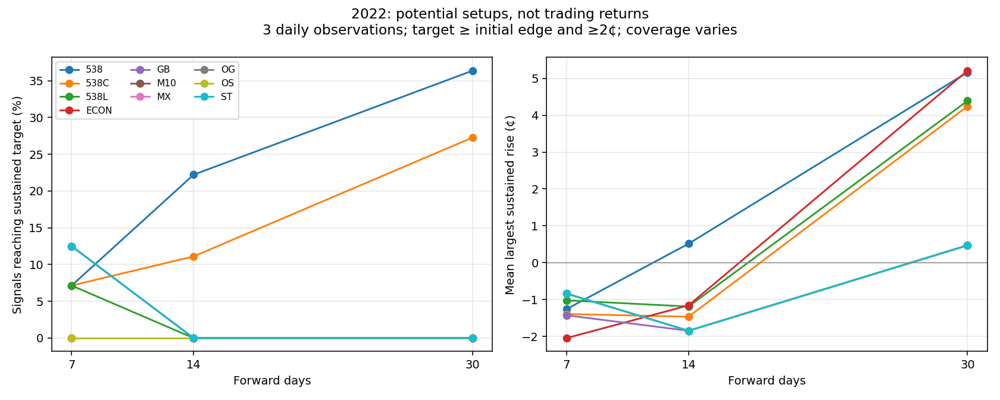

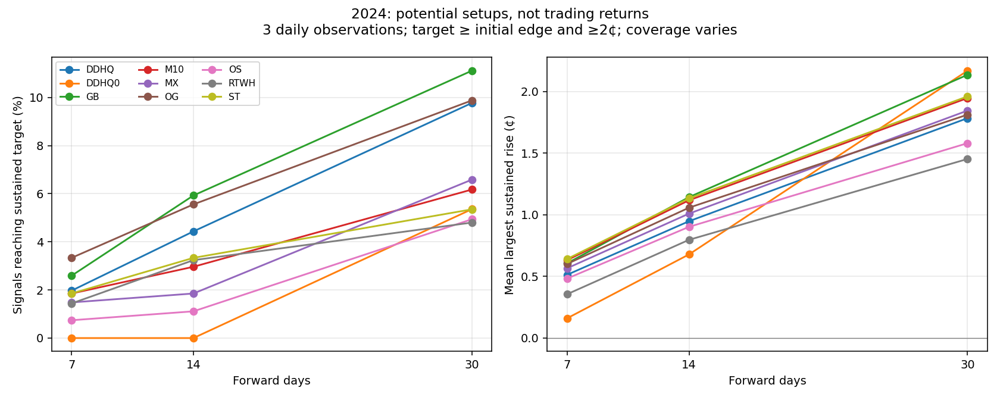

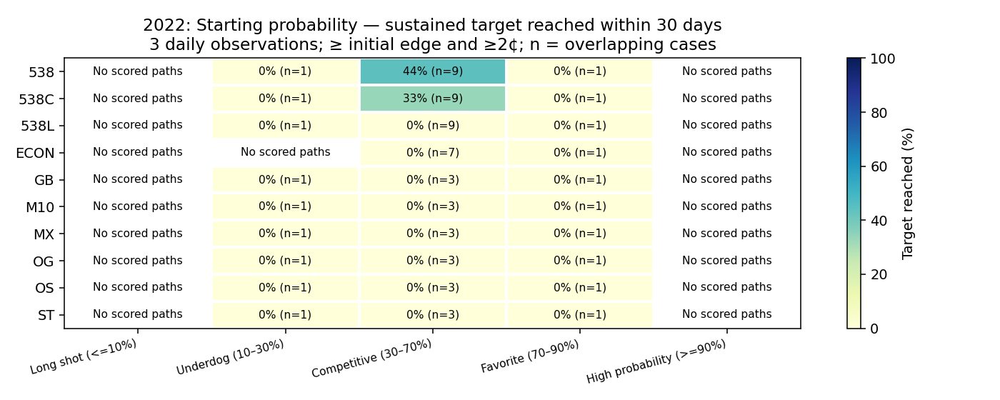

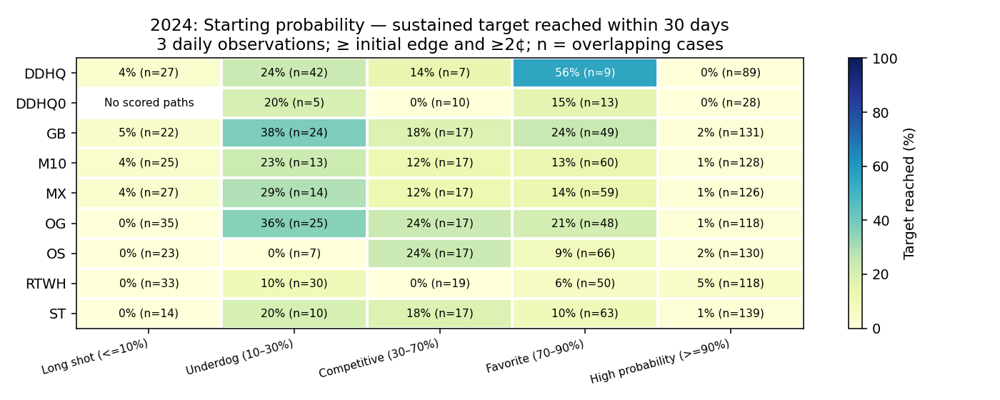

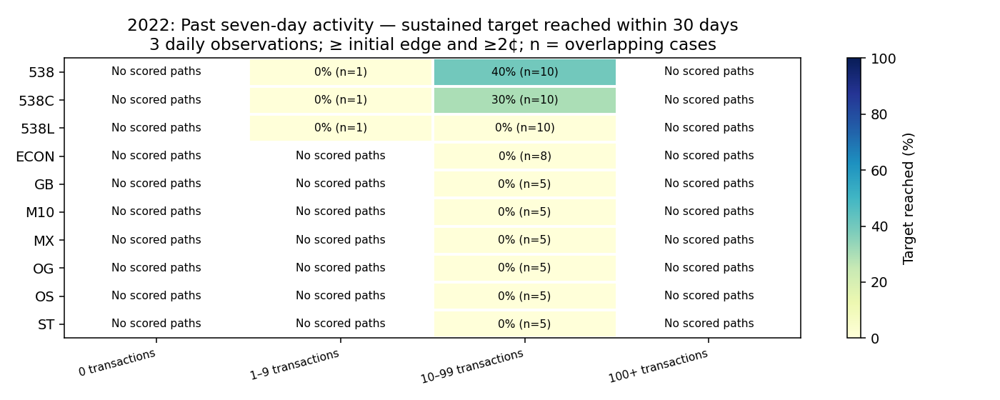

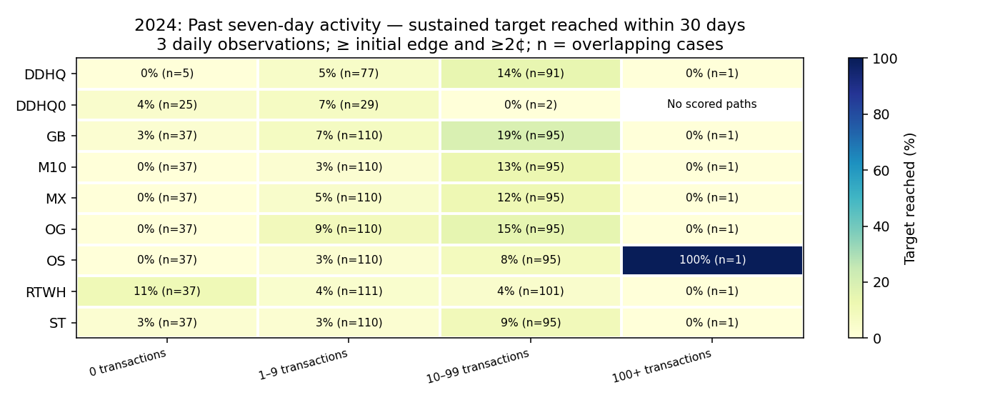

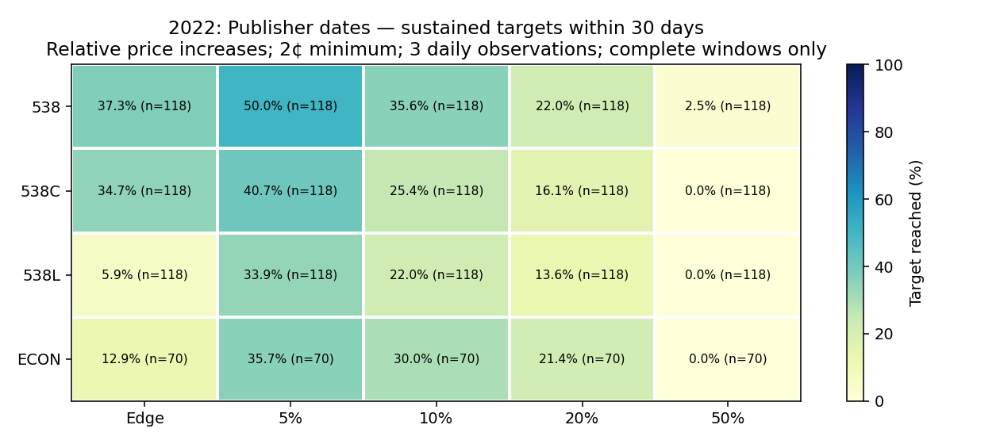

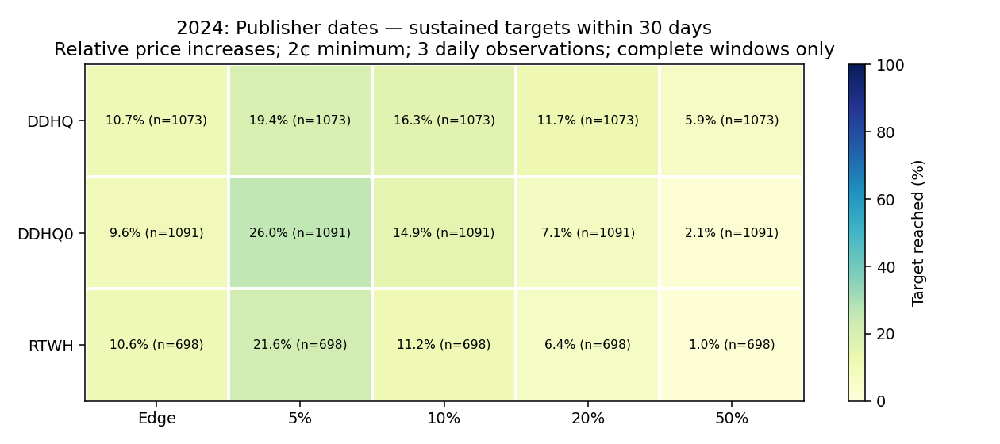

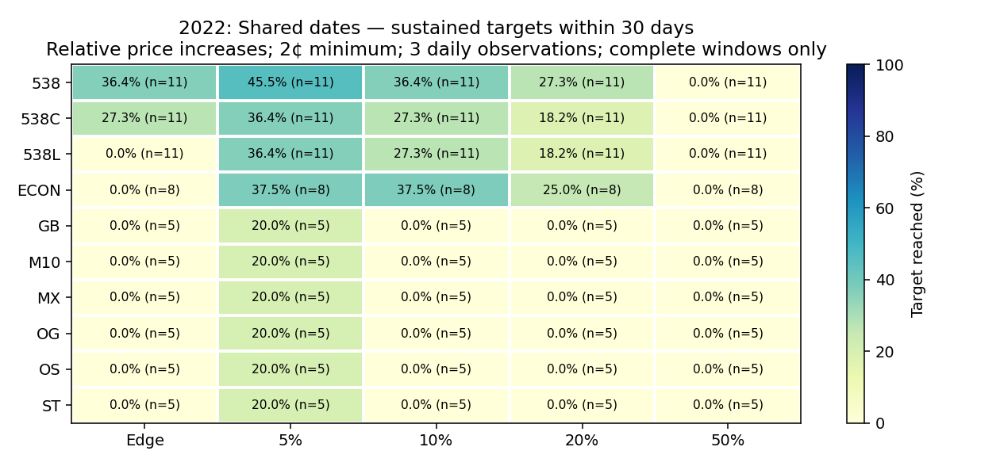

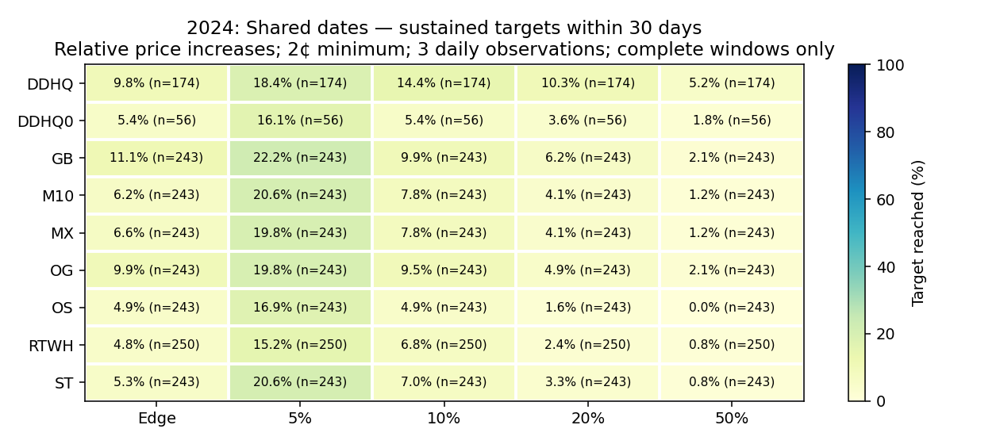

### 2022: 7-day window

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,69,14,8,7.143,-1.258,-1.189
538C,69,14,8,7.143,-1.392,-2.431
538L,69,14,8,7.143,-1.022,-2.121
ECON,15,7,4,0.000,-2.045,-3.930
GB,58,8,6,0.000,-1.427,-2.610
M10,58,8,6,12.500,-0.838,-2.291
MX,58,8,6,12.500,-0.838,-2.291
OG,58,8,6,12.500,-0.838,-2.291
OS,58,8,6,0.000,-0.838,-2.291
ST,58,8,6,12.500,-0.838,-2.291


Model,Equal-market target (%),Matched signals,Matched target (%),Control target (%),Lift (pp)
538,2.500,0,—,—,—
538C,2.500,0,—,—,—
538L,12.500,0,—,—,—
ECON,0.000,0,—,—,—
GB,0.000,0,—,—,—
M10,16.667,0,—,—,—
MX,16.667,0,—,—,—
OG,16.667,0,—,—,—
OS,0.000,0,—,—,—
ST,16.667,0,—,—,—


Model,Days to target,Worst before target (¢),Median edge covered (×)
538,4.298,0.000,-0.339
538C,6.439,0.000,-0.258
538L,4.764,0.000,-0.135
ECON,—,—,-0.132
GB,—,—,-0.118
M10,4.764,0.000,-0.050
MX,4.764,0.000,-0.049
OG,4.764,0.000,-0.045
OS,—,—,-0.046
ST,4.764,0.000,-0.045


### 2022: 14-day window

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,69,9,5,22.222,0.515,-2.728
538C,69,9,5,11.111,-1.465,-6.520
538L,69,9,5,0.000,-1.189,-7.205
ECON,15,6,4,0.000,-1.158,-8.947
GB,58,4,3,0.000,-1.848,-8.186
M10,58,4,3,0.000,-1.848,-8.186
MX,58,4,3,0.000,-1.848,-8.186
OG,58,4,3,0.000,-1.848,-8.186
OS,58,4,3,0.000,-1.848,-8.186
ST,58,4,3,0.000,-1.848,-8.186


... (15 outputs left out)

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
DDHQ,261,174,29,9.770,1.784,0.586
DDHQ0,56,56,28,5.357,2.169,1.434
GB,324,243,27,11.111,2.135,0.994
M10,324,243,27,6.173,1.947,0.871
MX,324,243,27,6.584,1.845,0.799
OG,324,243,27,9.877,1.812,0.659
OS,324,243,27,4.938,1.581,0.288
RTWH,334,250,28,4.800,1.453,0.038
ST,324,243,27,5.350,1.960,0.946


Model,Equal-market target (%),Matched signals,Matched target (%),Control target (%),Lift (pp)
DDHQ,9.770,132,6.061,0.868,5.192
DDHQ0,5.357,3,0.000,16.667,-16.667
GB,11.111,130,11.538,1.325,10.214
M10,6.173,109,3.670,1.654,2.016
MX,6.584,109,3.670,1.333,2.337
OG,9.877,154,7.143,4.394,2.749
OS,4.938,101,0.000,0.482,-0.482
RTWH,4.762,132,2.273,8.210,-5.937
ST,5.350,90,2.222,1.947,0.275


Model,Days to target,Worst before target (¢),Median edge covered (×)
DDHQ,20.118,-0.412,0.330
DDHQ0,21.667,-12.333,0.114
GB,15.926,-1.019,0.283
M10,15.400,-0.300,0.268
MX,18.250,-0.656,0.244
OG,15.167,-0.375,0.249
OS,20.250,-1.000,0.188
RTWH,15.000,0.000,0.282
ST,15.154,-0.346,0.260


Matched controls have nonpositive model edge, similar initial prices, the same calendar month and cycle, and come from other markets. Both groups face the signal’s exact target. Blank values mean insufficient matches.

In [9]:
from polymarket_signal_quality import METHOD as SIGNAL_METHOD, summary_table as signal_table
signal = research['signals']
display(Markdown(SIGNAL_METHOD))
table(pd.DataFrame([
    ['GB','Gaussian Bayesian'], ['ST','Matched Student-t'],
    ['OG','Older Gaussian'], ['OS','Older Student-t'],
    ['MX','Four-model mixture'], ['M10','Mixture with 10% polling mean shift'],
    ['538','538 Deluxe (2022)'], ['538C','538 Classic (2022)'], ['538L','538 Lite (2022)'],
    ['ECON','Economist original (2022; four states; Sep7–Oct30)'],
    ['RTWH','Race to the WH (2024)'], ['DDHQ0','DDHQ original (2024; May–July)'],
    ['DDHQ','DDHQ revised (2024; Aug27 onward)'],
],columns=['Code','Model']))
status = pd.read_parquet(OUT / 'signal_publisher_status.parquet')
status['Publisher'] = status.model.str.replace(r' (?:[A-Z]{2})$','',regex=True)
table(status.groupby(['cycle','Publisher','status'],as_index=False).agg(Rows=('rows','sum')))
for path in research['charts']:
    if path.name.startswith('signal_quality'):
        display(Image(filename=str(path)))
for (cycle, days), rows in signal['summary'].groupby(['cycle','horizon']):
    display(Markdown(f'### {cycle}: {days}-day window'))
    table(signal_table(rows))
    table(rows[['model','equal_market_hit_pct','matched','matched_hit_pct','baseline_pct','lift_pp']].rename(columns={
        'model':'Model','equal_market_hit_pct':'Equal-market target (%)','matched':'Matched signals',
        'matched_hit_pct':'Matched target (%)','baseline_pct':'Control target (%)','lift_pp':'Lift (pp)'}))
    table(rows[['model','days_to_hit','worst_before_hit_cents','median_edge_covered']].rename(columns={'model':'Model','days_to_hit':'Days to target','worst_before_hit_cents':'Worst before target (¢)','median_edge_covered':'Median edge covered (×)'}))
display(Markdown('Matched controls have nonpositive model edge, similar initial prices, the same calendar month and cycle, and come from other markets. Both groups face the signal’s exact target. Blank values mean insufficient matches.'))

### Supplemental publisher evidence: use sparse snapshots too

Every recovered dated snapshot is tested on its own date, even when only one supported case exists. Setups count sustained moves. Unknown means an incomplete path without a confirmed move, not a failure. Full-window rates use complete windows only. Repeated daily forecasts reuse paths.

In [10]:
from polymarket_signal_quality import NATIVE_METHOD, native_table
native = signal['native_detail']
display(Markdown(NATIVE_METHOD))
for (cycle, days), rows in signal['native_summary'].groupby(['cycle','horizon']):
    display(Markdown(f'#### {cycle}: {days} days after each publisher snapshot'))
    table(native_table(rows))
for (cycle, model), rows in native.query('horizon==30').groupby(['cycle','model']):
    display(Markdown(f'#### {cycle}: {model}, state evidence (30 days)'))
    stats=[]
    for state, g in rows.groupby('state'):
        complete=g[g.complete]
        stats.append({'State':state,'Dates':g.model_date.nunique(),
            'First forecast':g.model_date.min().strftime('%b %d'),
            'Last forecast':g.model_date.max().strftime('%b %d'),
            'Setups / signals':f'{int(g.confirmed.sum())} / {len(g)}',
            'Unknown':int((~g.complete & ~g.confirmed).sum()),
            'Full-window target':f'{100*complete.confirmed.mean():.1f}% (n={len(complete)})' if len(complete) else 'Not scored'})
    table(pd.DataFrame(stats))
display(Markdown('RTWH 2022 and 538 2024 have no recovered validated dated state probabilities. They are not excluded by a minimum sample count.'))

Supplemental publisher evidence uses every recovered dated snapshot during the June-to-election research season, even a single snapshot. Each forecast is evaluated only on its own date, using the first market observation within 36 hours after that date ends. No interpolation, stale carry-forward, minimum sample count, or requirement that another model exists is applied. Known publication/version restrictions still apply. The target remains the larger of the initial edge and 2 cents, sustained across three daily observations. This is a different observation set from the shared-date comparison and must not be used as a head-to-head ranking.

Confirmed setups count actually observed sustained moves, including those inside incomplete or election-truncated windows. An incomplete path without such a move is Unknown, not a failure. Target rates use only complete windows. Forecast-date counts, markets, and sample-size labels stay visible; daily updates and overlapping paths are related observations, not independent opportunities or profits.

#### 2022: 7 days after each publisher snapshot

Model,Dates,Markets,Setups / signals,Unknown,Full-window target,Evidence
538,129,13,19 / 871,639,6.6% (n=228),Overlapping observations
538C,129,13,15 / 871,640,5.3% (n=228),Overlapping observations
538L,129,13,3 / 871,643,1.3% (n=228),Overlapping observations
ECON,40,4,0 / 129,61,0.0% (n=68),Overlapping observations


#### 2022: 14 days after each publisher snapshot

Model,Dates,Markets,Setups / signals,Unknown,Full-window target,Evidence
538,129,13,43 / 871,700,13.5% (n=148),Overlapping observations
538C,129,13,37 / 871,703,11.5% (n=148),Overlapping observations
538L,129,13,8 / 871,715,0.0% (n=148),Overlapping observations
ECON,40,4,0 / 129,59,0.0% (n=70),Overlapping observations


#### 2022: 30 days after each publisher snapshot

... (18 outputs left out)

State,Dates,First forecast,Last forecast,Setups / signals,Unknown,Full-window target
AZ,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
CA,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
CT,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
DE,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
FL,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
HI,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
IN,39,Jun 02,Jul 18,4 / 39,0,10.3% (n=39)
MA,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
MD,39,Jun 02,Jul 18,0 / 39,0,0.0% (n=39)
MI,39,Jun 02,Jul 18,23 / 39,0,59.0% (n=39)


#### 2024: RTWH, state evidence (30 days)

State,Dates,First forecast,Last forecast,Setups / signals,Unknown,Full-window target
AZ,31,Jun 02,Oct 30,4 / 31,6,16.0% (n=25)
CA,31,Jun 02,Oct 30,0 / 31,6,0.0% (n=25)
CT,31,Jun 02,Oct 30,3 / 31,6,12.0% (n=25)
DE,31,Jun 02,Oct 30,4 / 31,6,16.0% (n=25)
FL,31,Jun 02,Oct 30,1 / 31,6,4.0% (n=25)
HI,31,Jun 02,Oct 30,0 / 31,6,0.0% (n=25)
IN,31,Jun 02,Oct 30,4 / 31,6,16.0% (n=25)
MA,31,Jun 02,Oct 30,0 / 31,6,0.0% (n=25)
MD,31,Jun 02,Oct 30,10 / 31,6,40.0% (n=25)
MI,31,Jun 02,Oct 30,4 / 31,6,16.0% (n=25)


RTWH 2022 and 538 2024 have no recovered validated dated state probabilities. They are not excluded by a minimum sample count.

### Compare several sustained price-rise targets

Signals require a positive model edge. Targets are 5%, 10%, 20%, and 50% above the starting price, each with a minimum increase of 2¢. These are relative changes, not percentage points. The original Edge target is the larger of the initial edge and 2¢. Every target needs three consecutive daily observations. Targets above $1 remain in the denominator as unattainable. These are observed setups, not demonstrated executable profits.

In [11]:
from polymarket_signal_quality import TARGET_METHOD, target_table
display(Markdown(TARGET_METHOD))
for (panel, cycle, days), rows in signal['target_summary'].groupby(['panel','cycle','horizon']):
    display(Markdown(f'#### {cycle}: {panel}, {days} days — complete-window rates'))
    table(target_table(rows))
    if panel == 'Publisher dates':
        display(Markdown('Confirmed setups, including witnessed moves in incomplete paths:'))
        table(target_table(rows, counts=True))
for (panel, cycle, band), rows in signal['target_probabilities'].query('horizon==30').groupby(['panel','cycle','probability_band']):
    display(Markdown(f'#### {cycle}: {panel}, starting probability {band}, 30 days'))
    table(target_table(rows))
for (cycle, band), rows in signal['target_activities'].query('horizon==30 and panel=="Shared dates"').groupby(['cycle','activity_band']):
    display(Markdown(f'#### {cycle}: prior activity {band}, 30 days'))
    table(target_table(rows))
display(Markdown('Exact thresholds, unattainable counts, state summaries and partial-window classifications are saved in the signal_quality_target research tables.'))

Percentage targets mean relative increases from the initial market price, not percentage-point increases in probability. Required rise = max(starting price × target percentage, 2 cents). Signals still require positive model edge, but percentage targets do not require the price to cover the whole edge. The original Edge target = max(initial model edge, 2 cents) remains alongside them. Every target must persist across three consecutive daily observations. No sale or executable return is assumed. At 10 cents, both 5% and 10% require a 2-cent rise; at 50 cents, they require 2.5 and 5 cents. Targets above the $1 payoff ceiling remain visible and count as unattainable, not silently excluded.

Targets are compared on identical signal observations within each panel and horizon. Full-window percentages use only complete windows; witnessed setups in partial publisher paths are reported separately. Shared check dates and publisher snapshot dates are different panels, not directly comparable model rankings. Repeated snapshots and overlapping windows are not independent samples. Previously reported matched-control lift applies only to the original Edge target, not these new percentage targets.

#### 2022: Publisher dates, 7 days — complete-window rates

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
538,228 / 11,6.579,17.982,7.018,2.632,0.439
538C,228 / 11,5.263,17.982,6.579,2.632,0.877
538L,228 / 11,1.316,14.912,6.140,2.193,0.877
ECON,68 / 4,0.000,11.765,1.471,0.000,0.000


Confirmed setups, including witnessed moves in incomplete paths:

Model,Signals / markets,Edge setups,5% setups,10% setups,20% setups,50% setups
538,871 / 13,19,59,22,8,1
538C,871 / 13,15,60,23,7,2
538L,871 / 13,3,50,21,5,2
ECON,129 / 4,0,9,1,0,0


#### 2022: Publisher dates, 14 days — complete-window rates

... (84 outputs left out)

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
DDHQ,91 / 29,14.286,27.473,20.879,14.286,6.593
DDHQ0,2 / 1,0.000,100.000,50.000,50.000,0.000
GB,95 / 27,18.947,34.737,20.000,11.579,2.105
M10,95 / 27,12.632,33.684,16.842,8.421,2.105
MX,95 / 27,11.579,30.526,15.789,7.368,1.053
OG,95 / 27,14.737,29.474,17.895,8.421,2.105
OS,95 / 27,8.421,26.316,11.579,4.211,0.000
RTWH,101 / 28,3.960,21.782,11.881,2.970,0.990
ST,95 / 27,9.474,32.632,14.737,6.316,1.053


#### 2024: prior activity 1–9 transactions, 30 days

Model,Scored / markets,Edge hit (%),5% hit (%),10% hit (%),20% hit (%),50% hit (%)
DDHQ,77 / 24,5.195,9.091,7.792,6.494,3.896
DDHQ0,29 / 22,6.897,20.690,6.897,3.448,3.448
GB,110 / 26,7.273,15.455,4.545,3.636,2.727
M10,110 / 26,2.727,12.727,2.727,1.818,0.909
MX,110 / 26,4.545,13.636,3.636,2.727,1.818
OG,110 / 26,9.091,14.545,5.455,3.636,2.727
OS,110 / 26,2.727,10.909,0.909,0.000,0.000
RTWH,111 / 27,3.604,11.712,4.505,2.703,0.901
ST,110 / 26,2.727,13.636,2.727,1.818,0.909


Exact thresholds, unattainable counts, state summaries and partial-window classifications are saved in the signal_quality_target research tables.

### What changes with starting price, activity, and edge size?

These compact tables use the 30-day window. The saved research tables also contain 7- and 14-day results. Activity is measured strictly before the signal. A zero count means no recorded transactions; missing archive coverage remains Unknown.

A 2¢ noise floor cannot be reached from prices above 98¢. Those observations remain visible in the high-probability band. Their low target rate is partly mechanical.

In [12]:
for key, grouping, label in [
    ('probabilities','probability_band','Starting market probability'),
    ('activities','activity_band','Prior seven-day trading activity'),
    ('edges','edge_band','Initial model edge')]:
    for (cycle, band), rows in signal[key].query('horizon==30').groupby(['cycle',grouping]):
        if rows.signals.sum()==0:
            continue
        display(Markdown(f'#### {cycle} — {label}: {band}'))
        table(signal_table(rows))

#### 2022 — Starting market probability: Competitive (30–70%)

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,33,9,3,44.444,6.410,-1.518
538C,33,9,3,33.333,5.285,-2.402
538L,33,9,3,0.000,5.465,-3.563
ECON,13,7,3,0.000,6.457,-4.538
GB,21,3,1,0.000,1.083,-13.327
M10,21,3,1,0.000,1.083,-13.327
MX,21,3,1,0.000,1.083,-13.327
OG,21,3,1,0.000,1.083,-13.327
OS,21,3,1,0.000,1.083,-13.327
ST,21,3,1,0.000,1.083,-13.327


#### 2022 — Starting market probability: Favorite (70–90%)

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,12,1,1,0.000,-3.535,-10.406
538C,12,1,1,0.000,-3.535,-10.406
538L,10,1,1,0.000,-3.535,-10.406
ECON,2,1,1,0.000,-3.535,-10.406
GB,11,1,1,0.000,-3.535,-10.406
M10,11,1,1,0.000,-3.535,-10.406
MX,11,1,1,0.000,-3.535,-10.406
OG,10,1,1,0.000,-3.535,-10.406
OS,13,1,1,0.000,-3.535,-10.406
ST,11,1,1,0.000,-3.535,-10.406


#### 2022 — Starting market probability: High probability (>=90%)

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,9,0,0,—,—,—
538C,8,0,0,—,—,—
538L,4,0,0,—,—,—
GB,4,0,0,—,—,—
M10,6,0,0,—,—,—
MX,6,0,0,—,—,—
OG,5,0,0,—,—,—
OS,9,0,0,—,—,—
ST,7,0,0,—,—,—


... (42 outputs left out)

#### 2024 — Initial model edge: 5–10¢

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
DDHQ,51,35,9,25.714,4.729,3.429
DDHQ0,33,33,19,0.000,0.998,0.995
GB,82,63,26,6.349,2.347,1.502
M10,88,74,26,6.757,3.003,2.550
MX,83,72,26,8.333,3.081,2.669
OG,85,72,25,12.500,2.281,1.720
OS,96,79,26,1.266,1.549,0.078
RTWH,67,55,23,1.818,2.562,1.544
ST,97,85,24,5.882,2.628,1.576


#### 2024 — Initial model edge: <2¢

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
DDHQ,123,81,18,7.407,0.779,-0.005
DDHQ0,5,5,3,40.000,1.500,1.100
GB,113,81,17,13.580,1.135,-0.025
M10,114,80,18,7.500,0.866,-0.396
MX,104,68,18,5.882,0.626,-0.009
OG,100,68,16,8.824,0.981,-0.632
OS,93,66,14,0.000,0.297,-1.152
RTWH,135,98,21,5.102,0.695,-0.170
ST,96,64,14,1.562,0.583,-0.213


### Same observations, state detail, and sensitivity

Pairwise comparisons retain only scored market/date observations available to both models. Models may choose opposite sides; the table states how often they agree. This avoids attributing a different observation mix to model quality. The sensitivity tables vary persistence and the noise threshold without choosing the best setting afterward.

In [13]:
for cycle, rows in signal['paired'].query('horizon==30').groupby('cycle'):
    display(Markdown(f'#### {cycle}: paired 30-day comparisons'))
    table(pd.DataFrame({
        'Models':rows.model_a+' / '+rows.model_b,'Cases':rows.cases,'Markets':rows.markets,
        'Target A/B (%)':rows.apply(lambda r:f'{r.hit_a:.1f} / {r.hit_b:.1f}',axis=1),
        'Rise A/B (¢)':rows.apply(lambda r:f'{r.rise_a:.2f} / {r.rise_b:.2f}',axis=1),
        'Same side (%)':rows.same_side_pct}))
for (cycle, state), rows in signal['states'].query('horizon==30').groupby(['cycle','state']):
    if rows.scored.sum()==0:
        continue
    display(Markdown(f'#### {cycle}: {state}, 30-day signals'))
    table(signal_table(rows))
for (cycle, persistence), rows in signal['sensitivity'].query('horizon==30').groupby(['cycle','persistence']):
    display(Markdown(f'#### {cycle}: {persistence} consecutive daily observations'))
    table(rows.pivot(index='model',columns='noise_cents',values='hit_pct').rename(columns=lambda x:f'{x:g}¢ floor: target (%)').reset_index())
display(Markdown('**Coverage exclusions**'))
audit = signal['audit']
table(audit.groupby(['cycle','reason'],as_index=False).size().rename(columns={'size':'Excluded checks'}))

#### 2022: paired 30-day comparisons

Models,Cases,Markets,Target A/B (%),Rise A/B (¢),Same side (%)
538 / 538C,11,4,36.4 / 27.3,5.16 / 4.24,81.818
538 / 538L,11,4,36.4 / 0.0,5.16 / 4.39,72.727
538 / ECON,8,3,37.5 / 0.0,5.99 / 5.21,87.500
538 / GB,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538 / M10,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538 / MX,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538 / OG,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538 / OS,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538 / ST,5,2,0.0 / 0.0,0.47 / 0.47,100.000
538C / 538L,11,4,27.3 / 0.0,4.24 / 4.39,90.909


#### 2024: paired 30-day comparisons

Models,Cases,Markets,Target A/B (%),Rise A/B (¢),Same side (%)
DDHQ / GB,162,27,8.6 / 12.3,1.75 / 1.82,64.815
DDHQ / M10,162,27,8.6 / 6.8,1.75 / 1.75,61.111
DDHQ / MX,162,27,8.6 / 7.4,1.75 / 1.61,58.025
DDHQ / OG,162,27,8.6 / 9.9,1.75 / 1.56,69.136
DDHQ / OS,162,27,8.6 / 5.6,1.75 / 1.21,52.469
DDHQ / RTWH,166,28,10.2 / 2.4,1.86 / 0.89,58.434
DDHQ / ST,162,27,8.6 / 4.3,1.75 / 1.71,60.494
DDHQ0 / GB,52,26,5.8 / 7.7,2.26 / 2.24,82.692
DDHQ0 / M10,52,26,5.8 / 3.8,2.26 / 1.49,76.923
DDHQ0 / MX,52,26,5.8 / 3.8,2.26 / 1.47,75.000


#### 2022: AZ, 30-day signals

Model,Signals,Scored,Scored markets,Target (%),Sustained rise (¢),End Δ (¢)
538,7,1,1,0.000,2.161,-8.059
538C,7,1,1,0.000,2.161,-8.059
538L,7,1,1,0.000,2.161,-8.059
ECON,3,1,1,0.000,2.161,-8.059


... (74 outputs left out)

#### 2024: 5 consecutive daily observations

model,1¢ floor: target (%),2¢ floor: target (%),3¢ floor: target (%)
DDHQ,10.920,8.621,7.471
DDHQ0,3.571,3.571,0.000
GB,15.226,10.700,9.877
M10,9.877,5.761,5.350
MX,8.642,6.173,5.350
OG,7.819,6.584,5.761
OS,4.938,3.292,2.881
RTWH,7.600,4.000,3.600
ST,7.819,5.350,5.350


**Coverage exclusions**

cycle,reason,Excluded checks
2022,No fresh unsuperseded forecast,160
2022,No valid fresh entry observation,83
2024,No fresh unsuperseded forecast,535


## Simple strategy: trade each model’s positive EV independently

This earlier execution-proxy experiment is retained for reference. The sustained-move section above is the signal-quality comparison. It trades both sides across all supported entry probabilities. Each model runs its own positions, without agreement filters. Price-proxy returns are not confirmed executable profits.

Each model trades independently on every reviewed state-win market for which it has a forecast. Other models' views or availability never determine its entries. Models can cover different markets, so totals are not a matched-universe ranking. Positions contain 100 shares, with at most one open side per market/model. Forecasts become available at 00:00 UTC after their recorded date; local forecasts update at the saved 12 cutoffs, and publishers use their available historical series. Between updates the most recent forecast is retained, with its date recorded. Prices and forecasts are processed chronologically. No election result is consulted to choose a trade.

Buy the side whose model probability exceeds its all-in purchase cost; the main rule uses strictly positive EV, not the previous two-cent threshold. Purchase cost is the observed price plus an assumed per-side execution allowance. Net sale proceeds are the observed price minus that allowance, floored at zero. These symmetric allowances proxy spread/slippage/fees, not historical executable bids/asks or actual fee schedules. The main assumption is 0.5 cents per side; zero and one cent per side are sensitivities. A missing/invalid price cannot create a trade. Exact zero/one quotes cannot open positions.

The main rule exits when net sale proceeds reach the latest model value of the held side. This can realize a loss after a model revision. A separate variant also exits at a 20% net gain over all-in entry cost. Decisions execute at the current observed price proxy, without using a later peak. A robustness variant requires the edge-exit condition on two consecutive usable observations no more than two days apart; it executes at the second price, not the first. There is no same-observation re-entry. A later observation may reopen either side, so all costs and turnover are retained.

Positions close at the last usable price before general-election day (Nov8,2022; Nov5,2024), no more than three days old. No new entries are permitted in the final 24 hours, which are reserved for exits. Unpriced final positions remain explicitly unscored. The entire simulation starts June1. Results compare the same entered lots with holding to that pre-election close and, when a binary contract payout is known, to settlement. These are matched-entry counterfactuals, not separately simulated buy-and-hold portfolios; repeated entries would overlap under holding.

Entry-price bands refer to the side purchased: <=10%, 10–30%, 30–70%, 70–90%, and >=90%. They are frozen when the trade opens. Totals assume funding every signal, with no capital constraint or interest; 100-share sizing means unequal dollars at risk across probability levels. Return on turnover is not a portfolio return. No fill/depth data, independent model selection, rare-event guarantee or pristine historical publication-vintage replay is claimed. One-day spikes may dominate price-proxy exits; inspect the confirmation sensitivity and state trades before drawing conclusions.

Code,Strategy model
GB,Gaussian Bayesian
ST,Matched Student-t
OG,Older Gaussian
OS,Older Student-t research model
MX,Four-model mixture
M10,Mixture + 10% polling mean shift
538,FiveThirtyEight Deluxe (2022)
RTWH,Race to the WH (2024)


OG and OS are also components of MX; these are alternative forecasts, not independent evidence.

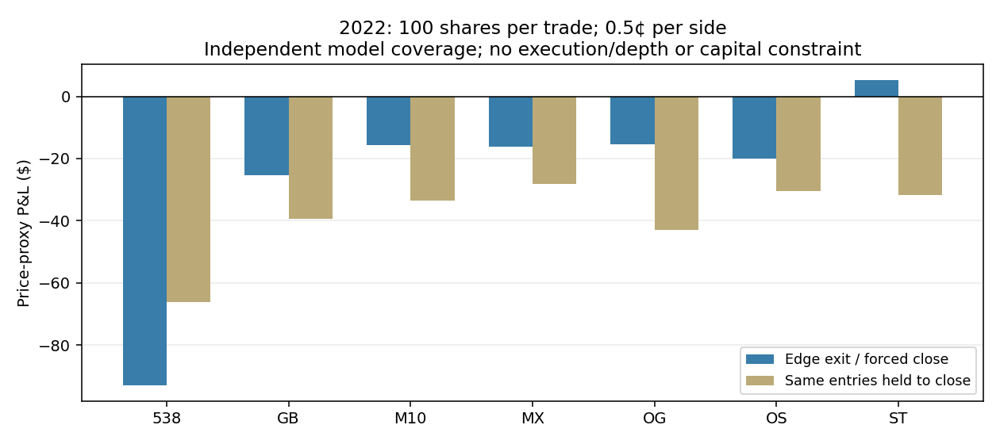

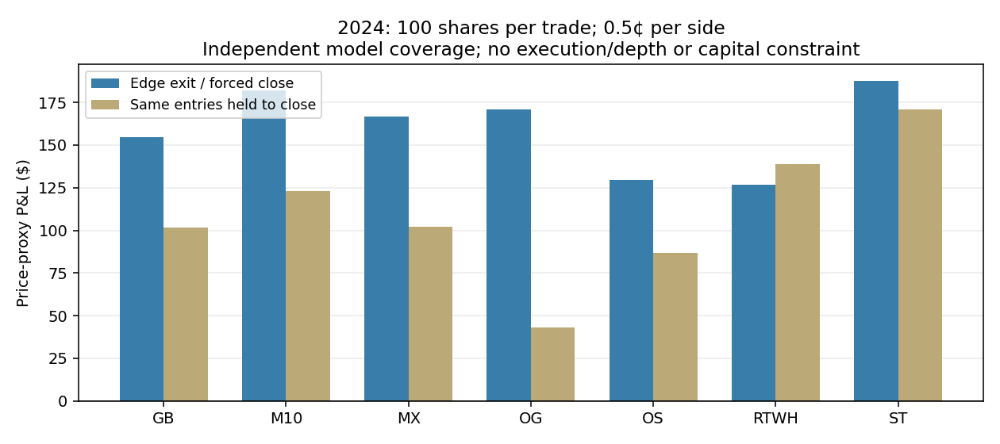

### 2022 — main rule: exit when the edge disappears

Model,Trades,Markets,Scored,Exit P&L ($),Hold to close ($)
538,42,13,42,-93.107,-66.238
GB,18,11,18,-25.283,-39.395
M10,21,11,21,-15.572,-33.636
MX,20,11,20,-16.178,-28.098
OG,25,11,25,-15.505,-43.076
OS,20,11,20,-20.027,-30.379
ST,21,11,21,5.314,-31.659


**The same entries held to settlement:** compare only lots with known contract payouts.

Model,Paired trades,Exit P&L ($),Hold to settlement ($)
538,0,—,—
GB,0,—,—
M10,0,—,—
MX,0,—,—
OG,0,—,—
OS,0,—,—
ST,0,—,—


### 2024 — main rule: exit when the edge disappears

Model,Trades,Markets,Scored,Exit P&L ($),Hold to close ($)
GB,59,27,59,154.750,101.500
M10,57,27,57,182.150,122.950
MX,52,27,52,166.450,102.000
OG,76,27,76,170.650,42.900
OS,43,27,43,129.650,86.700
RTWH,63,28,63,126.900,138.850
ST,53,27,53,187.750,170.700


... (91 outputs left out)

Race/side,Buy,Sell,Buy (¢),Sell (¢),P&L ($),Exit
AZ/D,Jun 01,Nov 04,70.000,75.000,5.000,Pre-election close
CA/D,Jun 01,Nov 04,91.000,97.450,6.450,Pre-election close
CT/D,Jun 01,Oct 07,91.000,97.800,6.800,Edge gone
CT/D,Oct 16,Nov 04,98.000,97.950,-0.050,Pre-election close
DE/D,Jun 01,Aug 13,91.000,95.500,4.500,Edge gone
DE/R,Aug 14,Nov 04,4.500,2.650,-1.850,Pre-election close
FL/R,Jun 01,Jun 13,88.000,88.000,0.000,Edge gone
FL/D,Jun 14,Nov 04,12.000,9.000,-3.000,Pre-election close
HI/D,Jun 01,Nov 04,92.000,98.850,6.850,Pre-election close
IN/R,Jun 01,Jul 16,92.000,93.000,1.000,Edge gone


### 2024 — ST: every main-rule trade

Race/side,Buy,Sell,Buy (¢),Sell (¢),P&L ($),Exit
CA/D,Jun 02,Nov 04,91.000,97.450,6.450,Pre-election close
CT/D,Jun 02,Nov 04,91.000,97.950,6.950,Pre-election close
DE/D,Jun 02,Nov 04,91.000,96.350,5.350,Pre-election close
FL/R,Jun 02,Oct 10,88.000,89.000,1.000,Edge gone
FL/D,Oct 13,Oct 16,11.000,10.000,-1.000,Edge gone
FL/R,Oct 17,Oct 24,89.500,91.000,1.500,Edge gone
FL/D,Oct 25,Nov 04,9.000,9.000,-0.000,Edge gone
HI/D,Jun 02,Nov 04,92.000,98.850,6.850,Pre-election close
IN/R,Jun 02,Nov 04,92.000,96.300,4.300,Pre-election close
MA/D,Jun 02,Nov 04,92.000,97.500,5.500,Pre-election close


Source dates, entry EV, forecasts at exit, positions, costs and all variants are saved in edge_strategy_*.parquet.


In [14]:
from polymarket_edge_strategy import METHOD as EDGE_METHOD, summary_table as edge_summary, trade_table as edge_trades
edge = research['edge_strategy']
display(Markdown(EDGE_METHOD))
table(pd.DataFrame([
    ['GB','Gaussian Bayesian'], ['ST','Matched Student-t'],
    ['OG','Older Gaussian'], ['OS','Older Student-t research model'],
    ['MX','Four-model mixture'], ['M10','Mixture + 10% polling mean shift'],
    ['538','FiveThirtyEight Deluxe (2022)'], ['RTWH','Race to the WH (2024)'],
],columns=['Code','Strategy model']))
display(Markdown('OG and OS are also components of MX; these are alternative forecasts, not independent evidence.'))
MAIN_EDGE = 'rule=="Edge" and cost_cents==0.5 and confirmations==1'
for path in research['charts']:
    if path.name.startswith('edge_strategy'):
        display(Image(filename=str(path)))
for cycle, rows in edge['summary'].query(MAIN_EDGE).groupby('cycle'):
    display(Markdown(f'### {cycle} — main rule: exit when the edge disappears'))
    table(edge_summary(rows))
    display(Markdown('**The same entries held to settlement:** compare only lots with known contract payouts.'))
    table(rows[['model','settlement_scored','exit_pnl_settlement_paired','hold_settlement_pnl']].rename(columns={
        'model':'Model','settlement_scored':'Paired trades','exit_pnl_settlement_paired':'Exit P&L ($)','hold_settlement_pnl':'Hold to settlement ($)'}))
display(Markdown('### Same-state comparison across models'))
for cycle, rows in edge['matched_summary'].query(MAIN_EDGE).groupby('cycle'):
    coverage = edge['matched_coverage'].query('cycle==@cycle').iloc[0]
    display(Markdown(f'**{cycle} — {coverage.states} shared states.** Forecast update frequencies and chosen entries still differ.'))
    print('States:',coverage.included)
    table(edge_summary(rows))
for (cycle, model), rows in edge['bands'].query(MAIN_EDGE).groupby(['cycle','model']):
    display(Markdown(f'### {cycle} — {model}: entry-price bands'))
    table(rows[['band','trades','pnl','hold_close_pnl','hold_settlement_pnl','settlement_scored']].rename(columns={
        'band':'Entry band','trades':'Trades','pnl':'Exit P&L ($)','hold_close_pnl':'Hold to close ($)',
        'hold_settlement_pnl':'Hold to settlement ($)','settlement_scored':'Payouts known'}))
for cycle, rows in edge['states'].query(MAIN_EDGE).groupby('cycle'):
    display(Markdown(f'### {cycle} — state-level edge-exit P&L ($)'))
    table(rows.pivot(index='state',columns='model',values='pnl').reset_index())
display(Markdown('### Cost, profit-target and confirmation sensitivities'))
for (cycle, rule, cost, confirm), rows in edge['summary'].groupby(['cycle','rule','cost_cents','confirmations']):
    if rule=='Edge' and cost==0.5 and confirm==1:
        continue
    display(Markdown(f'**{cycle} · {rule} · {cost:g}¢ per side · {confirm} observation(s)**'))
    table(edge_summary(rows))
for (cycle, model), rows in edge['trades'].query(MAIN_EDGE).groupby(['cycle','model']):
    display(Markdown(f'### {cycle} — {model}: every main-rule trade'))
    table(edge_trades(rows))
print('Source dates, entry EV, forecasts at exit, positions, costs and all variants are saved in edge_strategy_*.parquet.')


## Can model-backed long shots rise before resolution?

This is an exploratory price-path study with preset entry and exit rules. A later observed price is not proof of a fillable trade.

This exploratory test asks whether model-backed long shots later rose in price. It does not estimate election-win accuracy or prove executable profits. Entry cohorts use saved model check dates from June through October. A date-only forecast is used only after the following UTC midnight. Entry is the first daily price observation within 36 hours after that time. The side must cost 1–10 cents at entry; sub-cent outcomes are excluded. The fixed signal requires model value at least 2 cents above that entry proxy. All models are shown separately, alongside buying every eligible long shot. No final election outcome is used to select entries.

The preset exit target is twice the entry price. A target hit requires a strictly later daily observation at or above that level, before November 3 00:00 UTC. The simulated exit is credited at the target, not the hindsight peak. Otherwise use the final observed price before that deadline, no more than seven days old. Missing or drained-pool observations prevent claiming a complete path. Daily snapshots can miss intraday target touches; observed prices are not executable bids/asks or evidence of depth. Complemented Democratic-win prices proxy the Republican side; historical sell quotes are unavailable.

The summary reports observed target touches, whether two consecutive observations within two days both reached the target, price direction after 7/14/30 days, and equal-share gross exit-minus-entry. Forward comparisons use a price at or before each horizon no more than two days old; horizons after the deadline stay missing. Worst observed changes describe the full price path, not losses on an already closed position. A configurable round-trip cost sensitivity subtracts 0, 1 or 2 cents per share; these are assumptions, not reconstructed historical fees. Overlapping entry dates reuse the same markets, capital and future paths: rows are not independent trades or a deployable portfolio. Model probabilities value final resolution and do not estimate the probability or timing of a temporary price rise. Parameters are exploratory choices, not optimized or out-of-sample validated.

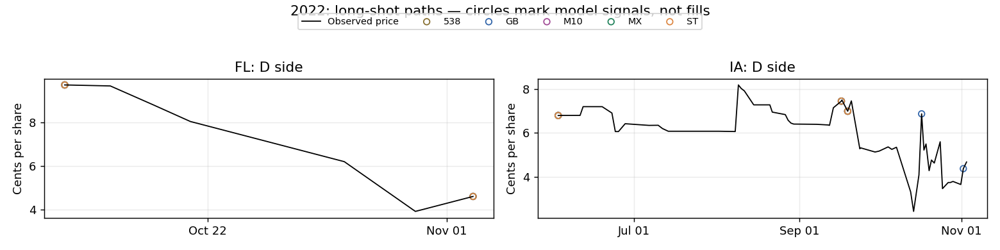

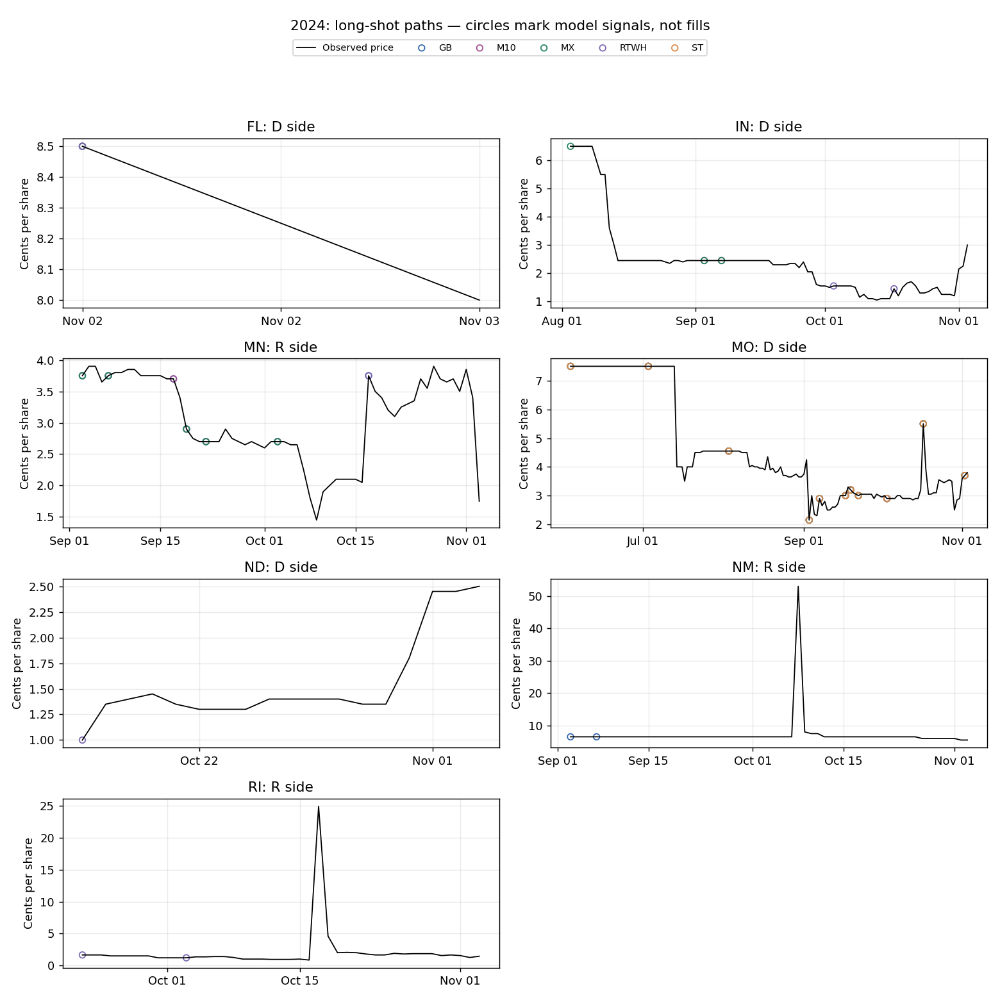

### 2022 — assumed round-trip cost: 0¢ per share

Model,Signals,Markets,Scored,Doubled (%),Net/share (¢)
538,1,1,1,0.000,-5.113
All long shots,10,3,9,11.111,-2.572
GB,7,2,6,0.000,-2.374
M10,5,2,4,0.000,-3.087
MX,5,2,4,0.000,-3.087
ST,5,2,4,0.000,-3.087


### 2022 — assumed round-trip cost: 1¢ per share

Model,Signals,Markets,Scored,Doubled (%),Net/share (¢)
538,1,1,1,0.000,-6.113
All long shots,10,3,9,11.111,-3.572
GB,7,2,6,0.000,-3.374
M10,5,2,4,0.000,-4.087
MX,5,2,4,0.000,-4.087
ST,5,2,4,0.000,-4.087


### 2022 — assumed round-trip cost: 2¢ per share

Model,Signals,Markets,Scored,Doubled (%),Net/share (¢)
538,1,1,1,0.000,-7.113
All long shots,10,3,9,11.111,-4.572
GB,7,2,6,0.000,-4.374
M10,5,2,4,0.000,-5.087
MX,5,2,4,0.000,-5.087
ST,5,2,4,0.000,-5.087


... (31 outputs left out)

State/side,Signal date,Entry (¢),Model (¢),Peak (¢),Doubled,Exit Δ (¢)
FL/D,Oct 31,8.500,19.000,8.000,No,-0.500
IN/D,Oct 01,1.550,6.600,3.000,No,1.450
IN/D,Oct 15,1.450,3.800,3.000,Yes,1.450
MN/R,Oct 15,3.750,6.100,3.900,No,-2.000
MO/D,Oct 01,2.900,4.900,5.500,No,0.900
ND/D,Oct 15,1.000,4.100,2.500,Yes,1.000
RI/R,Sep 20,1.650,4.700,24.950,Yes,1.650
RI/R,Oct 01,1.200,4.100,24.950,Yes,1.200


### 2024 — ST: every selected case

State/side,Signal date,Entry (¢),Model (¢),Peak (¢),Doubled,Exit Δ (¢)
MO/D,Jun 01,7.500,14.052,7.500,No,-3.700
MO/D,Jul 01,7.500,13.115,7.500,No,-3.700
MO/D,Aug 01,4.550,17.597,5.500,No,-0.750
MO/D,Sep 01,2.150,10.136,5.500,Yes,2.150
MO/D,Sep 05,2.900,6.562,5.500,No,0.900
MO/D,Sep 15,3.000,12.616,5.500,No,0.800
MO/D,Sep 17,3.200,12.201,5.500,No,0.600
MO/D,Sep 20,3.000,12.240,5.500,No,0.800
MO/D,Oct 01,2.900,11.563,5.500,No,0.900
MO/D,Oct 15,5.500,11.759,3.900,No,-1.700


Peak prices are hindsight diagnostics. Exit changes use the preset doubling target or deadline; incomplete paths stay blank.
Overlapping dates reuse the same markets. These are not independent trades or portfolio returns.


In [15]:
from polymarket_longshot_paths import METHOD as PATH_METHOD, summary_table as path_summary, cases_table, direction_table
paths = research['longshot_paths']
display(Markdown(PATH_METHOD))
for path in research['charts']:
    if path.name.startswith('longshot_price_paths'):
        display(Image(filename=str(path)))
for (cycle, cost), rows in paths['summary'].query('signal=="Selected"').groupby(['cycle','cost_cents']):
    display(Markdown(f'### {cycle} — assumed round-trip cost: {cost:g}¢ per share'))
    table(path_summary(rows))
for (cycle, signal), rows in paths['summary'].query('cost_cents==0').groupby(['cycle','signal']):
    display(Markdown(f'### {cycle} — {signal}: direction and target persistence'))
    table(direction_table(rows))
for (cycle, model), rows in paths['detail'].query('selected and model!="All long shots"').groupby(['cycle','model']):
    display(Markdown(f'### {cycle} — {model}: every selected case'))
    table(cases_table(rows))
print('Peak prices are hindsight diagnostics. Exit changes use the preset doubling target or deadline; incomplete paths stay blank.')
print('Overlapping dates reuse the same markets. These are not independent trades or portfolio returns.')


## Accuracy over time: competitive races and long shots

The following comparison holds states fixed across dates. This separates changes in predictions from changes in data coverage.

The main trend holds both states and models fixed from September 5 through November 3. A state must have every model, a valid market price and a known nonconflicting result at every check date. All models score the same events with equal state weights. This reduces coverage but prevents changing membership from masquerading as improving accuracy.

Competitive means Polymarket gave Democrats 30–70% on September 5. Long-shot races had a side at 10% or less on that date; that same side is followed afterward. These fixed groups can change competitiveness later. A separate hindsight group contains races whose final D-minus-R margin was within five points; it must not be used to select historical trades. The dynamic long-shot table instead selects the <=10% side anew at each date and shows its expected and actual wins, with counts. Dynamic membership changes and dates reuse outcomes; they are not independent calibration trials.

Brier is squared probability error against the observed winner; lower is better. Long-shot Brier equals the corresponding favorite's Brier, so it does not by itself measure rare-event skill. Expected upset counts provide complementary context. No trading returns are computed. Missing historical folds, publication vintages and the seven-day market/six-day publisher age limits still apply.

2022: 8 states across 8 dates. Included: CO, FL, NC, NH, NV, OH, PA, WI.
Excluded from this fixed panel: AZ, GA, IA, VT, WA
2024: 26 states across 8 dates. Included: CA, CT, DE, FL, HI, IN, MA, MD, MI, MN, MO, MS, MT, ND, NJ, NM, NV, NY, OH, PA, RI, TN, TX, UT, VA, WI.
Excluded from this fixed panel: AZ, WA, WY


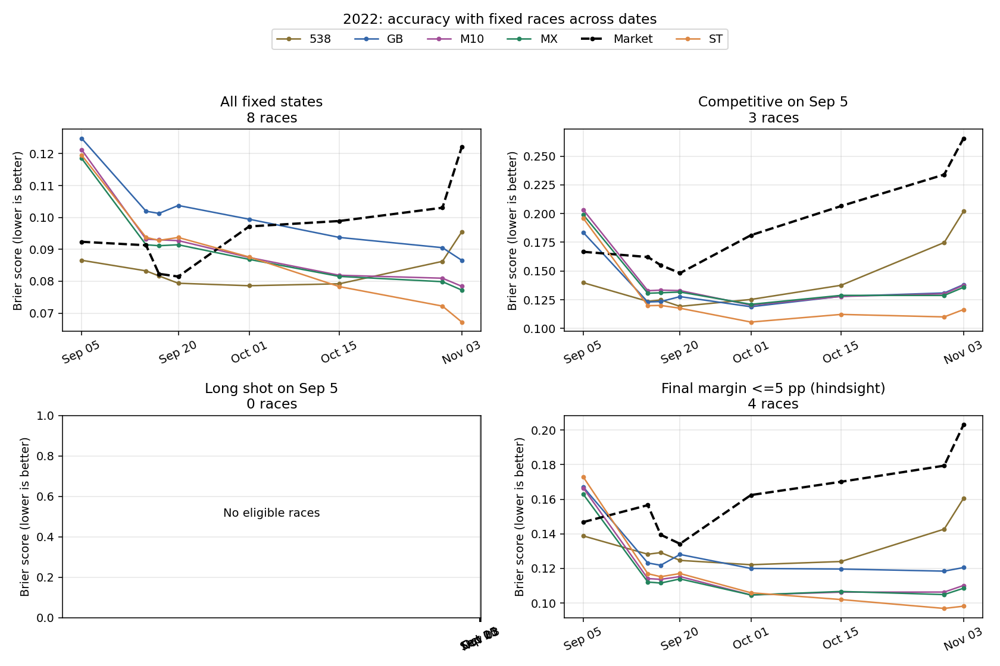

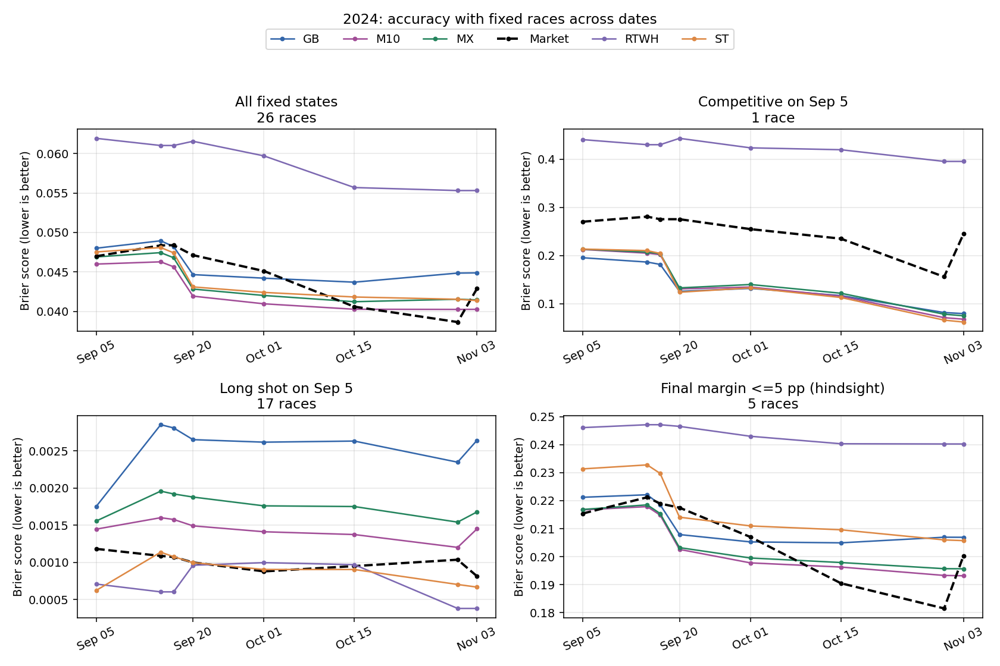

### 2022 — All fixed states (8 races)

Date,Market,GB,ST,MX,M10,538
Sep 05,0.092,0.125,0.120,0.119,0.121,0.087
Sep 15,0.091,0.102,0.094,0.091,0.093,0.083
Sep 17,0.082,0.101,0.093,0.091,0.093,0.082
Sep 20,0.081,0.104,0.094,0.091,0.093,0.079
Oct 01,0.097,0.099,0.088,0.087,0.087,0.079
Oct 15,0.099,0.094,0.078,0.082,0.082,0.079
Oct 31,0.103,0.091,0.072,0.080,0.081,0.086
Nov 03,0.122,0.087,0.067,0.077,0.078,0.095


### 2022 — Competitive on Sep 5 (3 races)

Date,Market,GB,ST,MX,M10,538
Sep 05,0.167,0.183,0.196,0.199,0.203,0.140
Sep 15,0.162,0.123,0.120,0.131,0.133,0.124
Sep 17,0.155,0.123,0.120,0.131,0.133,0.125
Sep 20,0.148,0.128,0.118,0.132,0.133,0.119
Oct 01,0.181,0.119,0.106,0.121,0.120,0.125
Oct 15,0.207,0.128,0.112,0.129,0.128,0.138
Oct 31,0.234,0.131,0.110,0.129,0.130,0.175
Nov 03,0.266,0.138,0.116,0.136,0.138,0.202


### 2022 — Final margin <=5 pp (hindsight) (4 races)

Date,Market,GB,ST,MX,M10,538
Sep 05,0.147,0.167,0.173,0.163,0.166,0.139
Sep 15,0.157,0.123,0.117,0.112,0.114,0.128
Sep 17,0.139,0.122,0.115,0.112,0.114,0.129
Sep 20,0.134,0.128,0.117,0.114,0.115,0.125
Oct 01,0.162,0.120,0.106,0.105,0.105,0.122
Oct 15,0.170,0.120,0.102,0.107,0.106,0.124
Oct 31,0.179,0.118,0.097,0.105,0.106,0.143
Nov 03,0.203,0.121,0.098,0.109,0.110,0.161


... (107 outputs left out)

**2024 — VA · final winner: D**

Date,Market,GB,ST,MX,M10,RTWH
Sep 05,0.003,0.002,0.000,0.002,0.002,0.000
Sep 15,0.003,0.003,0.000,0.002,0.003,0.001
Sep 17,0.003,0.003,0.000,0.002,0.003,0.001
Sep 20,0.003,0.003,0.000,0.002,0.003,0.002
Oct 01,0.002,0.003,0.000,0.002,0.003,0.001
Oct 15,0.004,0.001,0.000,0.001,0.001,0.000
Oct 31,0.004,0.003,0.000,0.002,0.003,0.000
Nov 03,0.002,0.003,0.000,0.002,0.002,0.000


**2024 — WI · final winner: D**

Date,Market,GB,ST,MX,M10,RTWH
Sep 05,0.029,0.098,0.065,0.057,0.062,0.034
Sep 15,0.031,0.097,0.058,0.053,0.059,0.033
Sep 17,0.029,0.109,0.068,0.063,0.068,0.033
Sep 20,0.034,0.106,0.064,0.060,0.066,0.038
Oct 01,0.034,0.112,0.068,0.065,0.072,0.031
Oct 15,0.055,0.131,0.085,0.081,0.089,0.033
Oct 31,0.119,0.181,0.137,0.128,0.141,0.057
Nov 03,0.068,0.187,0.147,0.137,0.150,0.057


In [16]:
from polymarket_accuracy_evolution import METHOD, score_table
study = research['evolution']
display(Markdown(METHOD))
for row in study['coverage'].itertuples():
    print(f'{row.cycle}: {row.states} states across {row.dates} dates. Included: {row.included}.')
    print('Excluded from this fixed panel:', row.excluded)
for path in research['charts']:
    if path.name.startswith('accuracy_evolution'):
        display(Image(filename=str(path)))
for (cycle, cohort), rows in study['metrics'].groupby(['cycle','cohort']):
    display(Markdown(f'### {cycle} — {cohort} ({rows.races.iloc[0]} races)'))
    table(score_table(rows))
display(Markdown('### Long shots selected at each date'))
display(Markdown('The same market-defined underdogs are scored by every model. Expected wins sum their probabilities. Counts matter: small groups and repeated outcomes do not establish rare-event calibration.'))
for (cycle, date), rows in study['longshots'].groupby(['cycle','check_date']):
    display(Markdown(f'**{cycle} — {date:%b %d}**'))
    table(rows[['model','races','expected_wins','actual_wins','brier']].rename(columns={
        'model':'Model','races':'Races','expected_wins':'Expected wins','actual_wins':'Actual wins','brier':'Brier'}))
display(Markdown('### Each state: Brier score through time'))
for (cycle, state), rows in study['panel'].groupby(['cycle','state']):
    display(Markdown(f'**{cycle} — {state} · final winner: {rows.final_winner.iloc[0]}**'))
    table(score_table(rows))


## Every state: market, models and final result

Each value is the probability of a Democratic win, in percent. The final winner appears in each heading. GB, ST, MX and M10 are freshly rerun for each check date. Tables below each state show market timestamps, quote ages and available publisher dates. No dropdowns or state filters are applied.

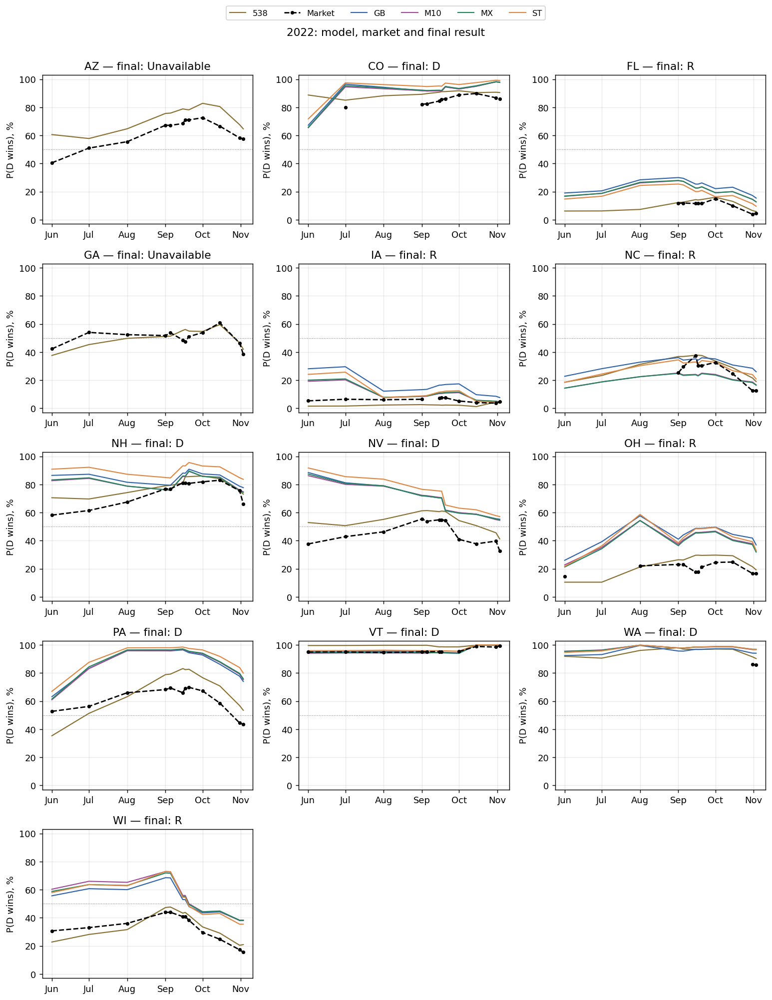

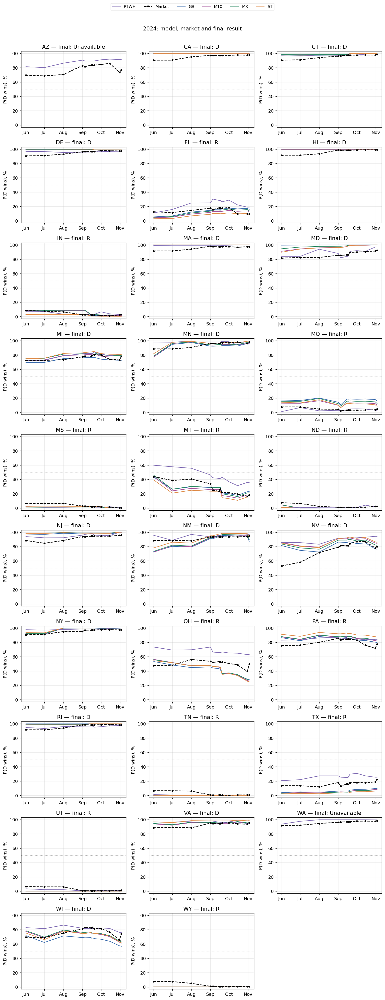

### 2022 — AZ · final winner: Unavailable

Date,Market (%),538
Jun 01,40.490,60.603
Jul 01,50.969,57.790
Aug 01,55.532,64.725
Sep 01,67.222,75.657
Sep 05,67.181,75.875
Sep 15,68.424,78.858
Sep 17,71.086,78.565
Sep 20,71.033,78.222
Oct 01,72.560,82.840
Oct 15,66.564,80.540


**Model proximity and accuracy across shared dates**

Model,Dates,Gap (pp),Brier,Market Brier


Check date,Market UTC,Age (days),538 date
Jun 01,May 28 18:06,4.246,Jun 01
Jul 01,Jun 30 22:17,1.072,Jul 01
Aug 01,Aug 01 18:27,0.231,Aug 01
Sep 01,Aug 30 16:55,2.295,Sep 01
Sep 05,Sep 04 23:47,1.009,Sep 05
Sep 15,Sep 14 04:16,1.822,Sep 15
Sep 17,Sep 17 16:09,0.327,Sep 17
Sep 20,Sep 18 17:07,2.287,Sep 20
Oct 01,Oct 01 20:03,0.164,Oct 01
Oct 15,Oct 15 20:50,0.131,Oct 15


Price source: Reconstructed FPMM marginal probability, before fees


... (242 outputs left out)

**Model proximity and accuracy across shared dates**

Model,Dates,Gap (pp),Brier,Market Brier
ST,12,2.115,0.000,0.001
M10,12,2.126,0.000,0.001
MX,12,2.133,0.000,0.001
GB,12,2.179,0.000,0.001


Check date,Market UTC,Age (days)
Jun 01,Jun 01 23:59,0.001
Jul 01,Jul 01 23:59,0.001
Aug 01,Aug 01 23:59,0.001
Sep 01,Sep 01 23:59,0.001
Sep 05,Sep 05 23:59,0.001
Sep 15,Sep 15 23:59,0.001
Sep 17,Sep 17 23:59,0.001
Sep 20,Sep 20 23:59,0.001
Oct 01,Oct 01 23:59,0.001
Oct 15,Oct 15 23:59,0.001


Price source: Original archived CLOB price-history observation; not an executable quote


In [17]:
for path in research['charts']:
    if path.name.startswith('state_probabilities'):
        display(Image(filename=str(path)))
for (cycle, state), rows in samples.groupby(['cycle','state']):
    display(Markdown(f'### {cycle} — {state} · final winner: {rows.final_winner.iloc[0]}'))
    table(state_comparison_table(rows).rename(columns={'Market':'Market (%)'}))
    display(Markdown('**Model proximity and accuracy across shared dates**'))
    group = near[near.cycle.eq(cycle) & near.state.eq(state)].sort_values('gap_pp')
    table(group[['model','dates','gap_pp','model_brier','market_brier']].rename(columns={
        'model':'Model','dates':'Dates','gap_pp':'Gap (pp)','model_brier':'Brier','market_brier':'Market Brier'}))
    timing = rows.drop_duplicates('check_date').set_index('check_date')
    timing = pd.DataFrame({'Market UTC':timing.market_time.dt.strftime('%b %d %H:%M'),'Age (days)':timing.market_age_days})
    ext = rows[~rows.model.isin(['GB','ST','MX','M10'])].assign(model_date=lambda q:q.model_date.dt.strftime('%b %d')).pivot(index='check_date',columns='model',values='model_date')
    for col in ext:
        timing[col+' date'] = ext[col]
    timing.index = timing.index.strftime('%b %d'); timing.index.name = 'Check date'
    table(timing.reset_index())
    print('Price source:', '; '.join(sorted(set(rows.price_source) - {''})))


## Coverage and limits

Only reviewed general-election party-winner mappings are scored. Independent-party definitions, special/runoff contracts, margins and Senate control require separate adapters. Those markets stay in the archive and audit. No probability, settlement or missing quote is fabricated.

In [18]:
audit = research['audit']
reasons = audit[audit.reason.ne('')].groupby(['cycle','reason'], as_index=False).agg(contracts=('market_id','nunique'))
table(reasons.rename(columns={'cycle':'Cycle','reason':'Reason','contracts':'Contracts'}))
print('The complete contract-level audit is saved in mapping_audit.parquet.')
missing = research['date_availability'].query('not available').groupby(['cycle','state','model','reason'],as_index=False).size().rename(columns={'size':'Dates'})
display(Markdown('**Missing model comparisons**'))
table(missing)

Cycle,Reason,Contracts
2022,Candidate or other outcome needs an explicit party/candidate adapter.,1
2022,Independent/party settlement requires candidate-specific historical mapping.,1
2022,Needs a historical joint/seat/margin distribution adapter.,33
2024,Candidate or other outcome needs an explicit party/candidate adapter.,29
2024,Election stage or special contest requires explicit review.,3
2024,Independent/party settlement requires candidate-specific historical mapping.,9
2024,Needs a historical joint/seat/margin distribution adapter.,150
2024,No unique state in the question.,3


The complete contract-level audit is saved in mapping_audit.parquet.


**Missing model comparisons**

cycle,state,model,reason,Dates
2022,AZ,GB,No exact-date local inference is available; not carried forward.,12
2022,AZ,M10,No exact-date local inference is available; not carried forward.,12
2022,AZ,MX,No exact-date local inference is available; not carried forward.,12
2022,AZ,ST,No exact-date local inference is available; not carried forward.,12
2022,GA,GB,No exact-date local inference is available; not carried forward.,12
2022,GA,M10,No exact-date local inference is available; not carried forward.,12
2022,GA,MX,No exact-date local inference is available; not carried forward.,12
2022,GA,ST,No exact-date local inference is available; not carried forward.,12
2024,AZ,GB,No exact-date local inference is available; not carried forward.,12
2024,AZ,M10,No exact-date local inference is available; not carried forward.,12


In [19]:
print('Portable data:', OUT.relative_to(ROOT))
print('Report:', research['report'].relative_to(ROOT))
print('All historical data and inference caches remain Git-ignored.')

Portable data: outputs/results/research/polymarket_history
Report: outputs/reports/research/polymarket_history/report.md
All historical data and inference caches remain Git-ignored.
